# **Grafo Epileptogénico bajo la Dinámica Normal**

En el notebook anterior la red se construía imponiendo una jerarquía, un grafo dirigido acíclico (DAG):

$$
A_{ij}=1 \iff x_{0,j}<x_{0,i},\ i\neq j .
$$

Aquí **no se impone ninguna dirección**: todas las regiones se conectan con todas ($A_{ij}=1\ \forall i\neq j$) y dejamos que sea la propia dinámica la que revele la estructura.

**Objetivos**

1. Construir el grafo de la *dinámica normal* (red completa) y estudiar su matriz de adyacencia.
2. Analizar componentes conexas y comunidades, para identificar **qué regiones entran en crisis**.
3. Añadir ruido y estudiar cómo las regiones epileptogénicas **reclutan** a las sanas: en qué orden, en qué dirección y si la dinámica reconstruye el DAG impuesto antes.
4. Acercar el análisis a Proix et al. (2014): predicción analítica del reclutamiento, diagramas $(x_0,K)$, conectividad estructural no trivial (SBM y conectoma real) y validación con el Epileptor completo.

**Modelo:** Epileptor 2D con acoplamiento de permitividad (Ec. 8 de Proix et al. 2014), con $I_1=3.1$ y umbral $x_0=2.91$, red completa con acoplamiento normalizado $K/N$ y ruido gaussiano aditivo en $x$ y $z$.

> **Tiempo de ejecución:** el integrador usa `numba` (Colab lo trae instalado). Todo el notebook tarda del orden de 30–40 min en Colab. Las simulaciones son vectorizadas: $M$ realizaciones en paralelo.

# **Importación de Librerías y Semillas**

In [1]:
from pathlib import Path
import time, io, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from networkx.algorithms.community import (louvain_communities, greedy_modularity_communities,
                                           asyn_lpa_communities, modularity)
from scipy.special import expit, comb
from scipy.optimize import brentq
from scipy.cluster.vq import kmeans2
from scipy.signal import lfilter
from scipy.stats import spearmanr, ConstantInputWarning
from numba import njit, prange          # en Colab viene instalado; en local: pip install numba

warnings.filterwarnings("ignore", message="Mean of empty slice")       # condiciones sin ninguna crisis
warnings.filterwarnings("ignore", category=ConstantInputWarning)       # correlaciones con K_c constante

SEED = 42
rng = np.random.default_rng(SEED)

FIG_DIR = Path("figuras")
FIG_DIR.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 220)

# **Modelo matemático**

Para $i=0,\ldots,N-1$ (Proix et al. 2014, Ec. 8, más ruido aditivo):

$$
dx_i=\left(-x_i^3-2x_i^2+1-z_i+I_1\right)dt+\sigma_x\,dW_i^{x},
$$

$$
dz_i=\frac{1}{\tau_0}\left[h(x_i)-z_i-\frac{K}{N}\sum_{j}A_{ij}\,(x_j-x_i)\right]dt+\sigma_z\,dW_i^{z},
$$

$$
h(x)=x_{0,i}+\frac{3}{1+\exp\!\left(\frac{-x-0.5}{0.1}\right)},\qquad \tau_0=2857,\qquad I_1=3.1 .
$$

- $x_{0,i}<2.91$: la región tiene **crisis espontáneas recurrentes** (epileptogénica).
- $x_{0,i}>2.91$: la región está en su **equilibrio sano**. En $x_0=2.91$ ocurre una bifurcación SNIC.

**Dinámica normal:** $A_{ij}=1$ para todo $i\neq j$ y $A_{ii}=0$. La diagonal no influye, porque $x_i-x_i=0$.

# **Parámetros**

In [2]:
TAU0 = 2857.0
I1 = 3.1
X0_C = 2.91                           # bifurcación SNIC (Proix et al. 2014)
UMBRAL_ON, UMBRAL_OFF = -0.5, -1.0    # histéresis: inicio y fin de una crisis
R = 30                                # realizaciones por condición

# **Elementos Básicos**

In [3]:
def h(x, x0):
    return x0 + 3.0 * expit((np.asarray(x) + 0.5) / 0.1)

def nulclina_x(x):
    return -x**3 - 2*x**2 + 1 + I1

Z_RODILLA = nulclina_x(-4.0 / 3.0)    # z de la rodilla inferior de la nulclina de x

def generate_x0(N=10, seed=42):
    if N < 2:
        raise ValueError("N debe ser >= 2.")
    local_rng = np.random.default_rng(seed)
    x0 = local_rng.normal(2.5, 0.5, N)
    x0[0] = 2.3
    x0[1] = 2.4
    if N > 2:
        x0[2:] = local_rng.uniform(2.9, 3.5, N - 2)
    return x0

N = 10
x0 = generate_x0(N, SEED)
foco = x0 < X0_C
sanas = ~foco

print("x0 =", x0)
print("Regiones epileptogénicas (foco):", np.where(foco)[0])
print("Regiones sanas:", np.where(sanas)[0])
print(f"z de la rodilla: {Z_RODILLA:.4f}")

x0 = [2.3   2.4   3.122 3.456 3.286 3.394 3.166 3.036 3.233 2.938]
Regiones epileptogénicas (foco): [0 1]
Regiones sanas: [2 3 4 5 6 7 8 9]
z de la rodilla: 2.9148


# **Verificación del modelo: un nodo aislado**

Los puntos fijos cumplen $-x^3-2x^2+1+I_1=h(x)$. Se comprueba que el modelo reproduce el umbral $x_0=2.91$ del paper.

In [4]:
def puntos_fijos(x0_val, xmin=-3.0, xmax=2.0, n=5001):
    g = lambda x: nulclina_x(x) - h(x, x0_val)
    xs = np.linspace(xmin, xmax, n)
    gs = g(xs)
    idx = np.where(np.sign(gs[:-1]) != np.sign(gs[1:]))[0]
    return [brentq(g, xs[k], xs[k + 1]) for k in idx]

def jacobiano(x):
    s = expit((x + 0.5) / 0.1)
    return np.array([[-3*x**2 - 4*x, -1.0],
                     [3*s*(1 - s) / 0.1 / TAU0, -1.0 / TAU0]])

filas = []
for a in [2.3, 2.5, 2.8, 2.9, 2.92, 3.0, 3.2, 3.5]:
    for xs_ in puntos_fijos(a):
        estable = np.all(np.linalg.eigvals(jacobiano(xs_)).real < 0)
        filas.append({"x0": a, "x*": round(xs_, 3), "z*": round(float(h(xs_, a)), 3),
                      "estabilidad": "estable" if estable else "inestable"})
display(pd.DataFrame(filas))

,x0,x*,z*,estabilidad
0,2.30,-0.512,3.710,inestable
1,2.50,-0.545,3.668,inestable
2,2.80,-0.602,3.593,inestable
3,2.90,-0.626,3.561,inestable
4,2.92,-1.386,2.920,estable
5,2.92,-1.276,2.921,inestable
6,2.92,-0.632,3.554,inestable
7,3.00,-1.530,3.000,estable
8,3.00,-1.105,3.007,inestable
9,3.00,-0.656,3.522,inestable


## **Explicación geométrica del umbral**

La nulclina de $x$, $z=-x^3-2x^2+1+I_1$, tiene una **rodilla inferior** en $x=-4/3$, donde

$$
z_{\rm rodilla}=f(-4/3)=I_1-\tfrac{5}{27}=2.9148 .
$$

En la rama baja ($x\ll-0.5$) la sigmoide vale casi cero y $h(x)\approx x_0$, así que el reposo de una región está en $z^*\approx x_0$:

- si $x_0>z_{\rm rodilla}$, el reposo cae **sobre** la rodilla, en la rama estable: la región está sana;
- si $x_0<z_{\rm rodilla}$, la rama baja desaparece bajo el reposo: la región salta a la rama alta (crisis), $z$ sube hasta que la rama alta desaparece y vuelve a bajar. Eso son crisis recurrentes.

Por eso el umbral del paper es $x_0\approx2.91$, y por eso la **barrera** de una región sana es $x_{0,i}-z_{\rm rodilla}$: es cuánto tiene que bajar su $z$ (por ruido o por acoplamiento) para entrar en crisis.

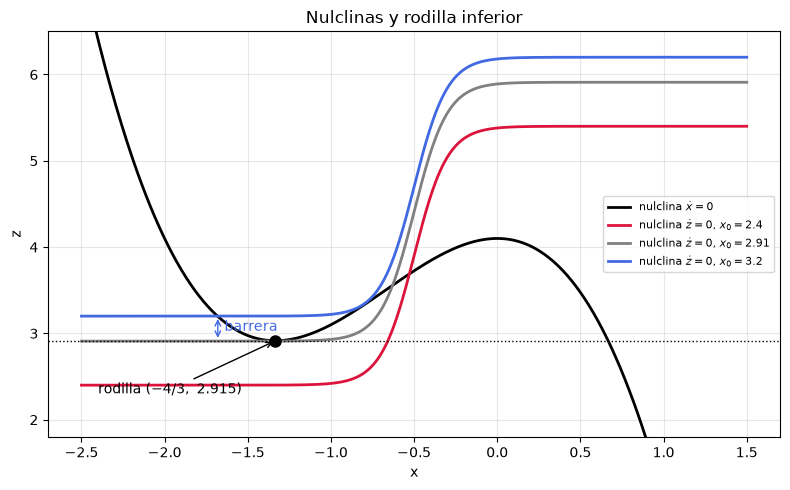

In [5]:
xx = np.linspace(-2.5, 1.5, 600)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(xx, nulclina_x(xx), "k", lw=2, label=r"nulclina $\dot x=0$")
for a, c in [(2.4, "crimson"), (X0_C, "0.5"), (3.2, "royalblue")]:
    ax.plot(xx, h(xx, a), color=c, lw=2, label=rf"nulclina $\dot z=0$, $x_0={a}$")
ax.axhline(Z_RODILLA, color="k", ls=":", lw=1)
ax.plot(-4/3, Z_RODILLA, "ko", ms=8)
ax.annotate(rf"rodilla $(-4/3,\ {Z_RODILLA:.3f})$", (-4/3, Z_RODILLA), xytext=(-2.4, 2.3),
            arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(-1.68, Z_RODILLA), xytext=(-1.68, 3.2), arrowprops=dict(arrowstyle="<->", color="royalblue"))
ax.text(-1.64, 3.03, "barrera", color="royalblue")
ax.set(xlabel="x", ylabel="z", ylim=(1.8, 6.5), title="Nulclinas y rodilla inferior")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_nulclinas.png", dpi=200)
plt.show()

# **1. Grafo de la Dinámica Normal**

$$
A_{ij}=
\begin{cases}
1,& i\neq j,\\
0,& i=j.
\end{cases}
$$

Como $A$ es simétrica, el grafo es **no dirigido**, así que desaparece el problema de convención $A$ vs $A^T$ del notebook anterior.

Componentes conexas de A: 1


,x0,grado,betweenness,clustering
nodo,,,,
0,2.300000,9,0.0,1.0
1,2.400000,9,0.0,1.0
2,3.122479,9,0.0,1.0
3,3.456059,9,0.0,1.0
4,3.286319,9,0.0,1.0
5,3.393657,9,0.0,1.0
6,3.166049,9,0.0,1.0
7,3.036343,9,0.0,1.0
8,3.232751,9,0.0,1.0


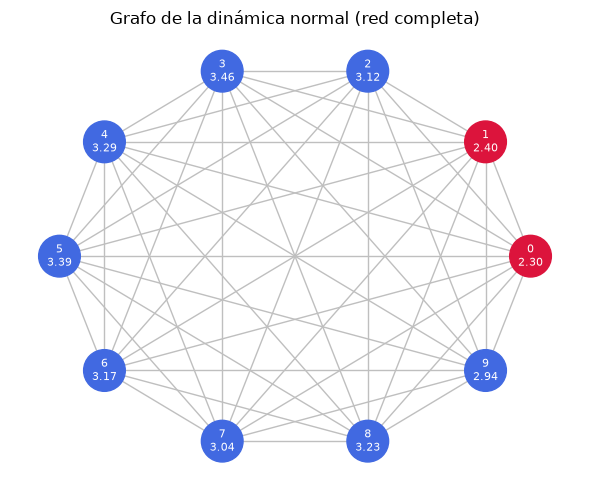

In [6]:
def adyacencia_completa(N):
    return np.ones((N, N), dtype=int) - np.eye(N, dtype=int)

A = adyacencia_completa(N)
G = nx.from_numpy_array(A)

print("Componentes conexas de A:", nx.number_connected_components(G))
metricas = pd.DataFrame({
    "x0": x0,
    "grado": pd.Series(dict(G.degree())),
    "betweenness": pd.Series(nx.betweenness_centrality(G)),
    "clustering": pd.Series(nx.clustering(G)),
})
metricas.index.name = "nodo"
display(metricas)

colores = np.where(foco, "crimson", "royalblue")
fig, ax = plt.subplots(figsize=(6, 5))
nx.draw_networkx(G, pos=nx.circular_layout(G), ax=ax, node_color=colores, node_size=900,
                 labels={i: f"{i}\n{x0[i]:.2f}" for i in range(N)},
                 font_size=8, font_color="white", edge_color="0.75")
ax.set_title("Grafo de la dinámica normal (red completa)")
ax.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_grafo_completo.png", dpi=200)
plt.show()

**Observación:** la red completa tiene **una sola componente conexa**, y todas las regiones tienen el mismo grado ($N-1$), betweenness 0 y clustering 1. La matriz estructural no distingue ninguna región, **por construcción**. Cualquier diferencia entre regiones viene de la dinámica, es decir, de $x_{0,i}$.

# **Integrador Euler–Maruyama en red (numba)**

Se simulan $M$ realizaciones en paralelo, cada una con sus propios $K$, $\sigma_x$ y $\sigma_z$, y con un generador aleatorio propio (xoroshiro128+ con Box–Muller). Así los resultados son reproducibles aunque se ejecuten en paralelo.

- **Condición inicial:** las regiones sanas parten en su punto fijo de reposo y las del foco en $x=-1.5$, $z=h(x)$.
- **Acoplamiento:** se guarda en formato disperso (CSR), así el costo escala con el número de aristas. Admite pesos $W_{ij}$ y puede actuar en $z$ (permitividad, por defecto) o en $x$ (`acople="x"`, Sección C18).
- **Detección de crisis con histéresis:** una región entra en crisis cuando $x_i>-0.5$ y sale cuando $x_i<-1.0$.
- **Salidas** (después de `t_trans`): número de crisis, cuántas empiezan con el foco en crisis (`foco_mask` define el foco), primer inicio, fracción del tiempo en crisis (*duty*) y, si `guardar=True`, las series $x$, $z$ y el estado de crisis.

In [7]:
def reposo(x0_val):
    return brentq(lambda x: nulclina_x(x) - h(x, x0_val), -3.0, -4.0/3.0)

def ci_reposo(x0):
    x = np.array([reposo(a) if a > X0_C else -1.5 for a in x0])
    return x, h(x, x0)

@njit(inline="always")
def _rotl(x, k):
    return (x << np.uint64(k)) | (x >> np.uint64(64 - k))

@njit(inline="always")
def _u01(s):
    # xoroshiro128+: s es el estado (2 x uint64) propio de cada realización
    s0 = s[0]; s1 = s[1]
    r = s0 + s1
    s1 ^= s0
    s[0] = _rotl(s0, 24) ^ s1 ^ (s1 << np.uint64(16))
    s[1] = _rotl(s1, 37)
    return ((r >> np.uint64(11)) + np.uint64(1)) * (1.0 / 9007199254740993.0)

@njit(inline="always")
def _normal(s):
    return np.sqrt(-2.0 * np.log(_u01(s))) * np.cos(2.0 * np.pi * _u01(s))

@njit(parallel=True, cache=True)
def _nucleo(x0, A_ptr, A_idx, A_val, K, sx, sz, xi, zi, estados, n, n_trans, dt, cada, guardar,
            es_foco, acople_en_x, guardar_x, n_on, n_on_foco, t_first, t_ict, t_foco, X, Z, S):
    M = K.shape[0]; N = x0.shape[0]
    sq = np.sqrt(dt)
    grado = np.zeros(N)
    for i in range(N):
        for p in range(A_ptr[i], A_ptr[i + 1]):
            grado[i] += A_val[p]
    for m in prange(M):
        s = estados[m]
        x = xi.copy(); z = zi.copy(); xn = np.empty(N); inicio = np.zeros(N, np.bool_)
        ict = x > UMBRAL_ON
        KN = K[m] / N
        for k in range(1, n + 1):
            foco_en_crisis = False
            for i in range(N):
                ac = -grado[i] * x[i]                       # sum_j W_ij (x_j - x_i)
                for p in range(A_ptr[i], A_ptr[i + 1]):
                    ac += A_val[p] * x[A_idx[p]]
                hx = x0[i] + 3.0 / (1.0 + np.exp(-(x[i] + 0.5) / 0.1))
                if acople_en_x:
                    xn[i] = x[i] + (-x[i]**3 - 2.0 * x[i]**2 + 1.0 - z[i] + I1 + KN * ac) * dt
                    z[i] += (hx - z[i]) / TAU0 * dt
                else:
                    xn[i] = x[i] + (-x[i]**3 - 2.0 * x[i]**2 + 1.0 - z[i] + I1) * dt
                    z[i] += (hx - z[i] - KN * ac) / TAU0 * dt
                if sx[m] > 0.0:
                    xn[i] += sx[m] * sq * _normal(s)
                if sz[m] > 0.0:
                    z[i] += sz[m] * sq * _normal(s)
            for i in range(N):
                x[i] = xn[i]
                on = (not ict[i]) and x[i] > UMBRAL_ON
                if x[i] > UMBRAL_ON:
                    ict[i] = True
                elif x[i] < UMBRAL_OFF:
                    ict[i] = False
                if k > n_trans:
                    if on:
                        n_on[m, i] += 1
                        if np.isinf(t_first[m, i]):
                            t_first[m, i] = (k - n_trans) * dt
                    if ict[i]:
                        t_ict[m, i] += 1
                        if es_foco[i]:
                            foco_en_crisis = True
                inicio[i] = on
            if k > n_trans:
                if foco_en_crisis:
                    t_foco[m] += 1
                for i in range(N):
                    if inicio[i] and foco_en_crisis:
                        n_on_foco[m, i] += 1
                if guardar and (k - n_trans) % cada == 0:
                    r = (k - n_trans) // cada - 1
                    if r < S.shape[0]:
                        for i in range(N):
                            S[r, m, i] = ict[i]
                            if guardar_x:
                                X[r, m, i] = x[i]; Z[r, m, i] = z[i]

def em_red(x0, A, K, sx=0.0, sz=0.0, T=50000, dt=0.1, M=1, seed=None, t_trans=5000, cada=10,
           guardar=False, guardar_x=True, acople="z", foco_mask=None):
    x0 = np.asarray(x0, float); N = len(x0)
    A = np.ascontiguousarray(A, float)
    es_foco = x0 < X0_C if foco_mask is None else np.asarray(foco_mask, bool)
    K, sx, sz = (np.ascontiguousarray(np.broadcast_to(np.asarray(v, float), (M,))) for v in (K, sx, sz))
    xi, zi = ci_reposo(x0)
    estados = np.random.default_rng(seed).integers(1, 2**63, size=(M, 2), dtype=np.uint64)
    n = int(round(T / dt)); n_trans = int(round(t_trans / dt))
    nrec = (n - n_trans) // cada if guardar else 0
    n_on = np.zeros((M, N), np.int64); n_on_foco = np.zeros((M, N), np.int64)
    t_first = np.full((M, N), np.inf); t_ict = np.zeros((M, N), np.int64); t_foco = np.zeros(M, np.int64)
    X = np.empty((nrec if guardar_x else 0, M, N), np.float32); Z = np.empty_like(X)
    S = np.empty((nrec, M, N), np.bool_)
    nz = A != 0
    A_ptr = np.concatenate([[0], np.cumsum(nz.sum(1))]).astype(np.int64)
    A_idx = np.nonzero(nz)[1].astype(np.int64); A_val = A[nz].astype(float)
    _nucleo(x0, A_ptr, A_idx, A_val, K, sx, sz, xi, zi, estados, n, n_trans, dt, cada, guardar,
            es_foco, acople == "x", guardar_x, n_on, n_on_foco, t_first, t_ict, t_foco, X, Z, S)
    T_ef = T - t_trans
    out = dict(n_on=n_on, n_on_foco=n_on_foco, t_first=t_first, T_ef=T_ef,
               duty=t_ict * dt / T_ef, duty_foco=t_foco * dt / T_ef)
    if guardar:
        out["t"] = np.arange(1, nrec + 1) * cada * dt
        out["ict"] = S
        if guardar_x:
            out["x"], out["z"] = X, Z
    return out

t0 = time.time()
_ = em_red(x0, A, 1.0, 0.02, 0.001, T=1000, M=2, seed=0)      # compilación
print(f"numba compilado en {time.time() - t0:.1f} s")

numba compilado en 0.3 s


## **Normalización del acoplamiento (B12)**

Se usa **$K/N$** y no $K/(N-1)$, por tres razones:

1. En la red completa $\frac{K}{N}\sum_j(x_j-x_i)=K\,(\bar x - x_i)$ con $\bar x=\frac1N\sum_j x_j$ el campo medio, incluyendo a $i$. Es la forma estándar de campo medio y la que se usará para estudiar la varianza empírica cuando $N\to\infty$.
2. Con $N$ fijo, ambas solo difieren en un factor $N/(N-1)$, que no cambia ninguna conclusión cualitativa.
3. En Proix et al. (2014) el acoplamiento es $K\sum_j(x_j-x_i)$ sin normalizar. Nuestro $K$ corresponde a un $K_{\rm paper}=K/N$ por arista.

Para las redes con pesos (Sección C15) los pesos se reescalan para que la fuerza media de un nodo sea $N-1$, igual que en la red completa. Así el mismo $K$ tiene el mismo significado en todas las estructuras.

In [8]:
K_VIEJO = 0.1      # BASE_K del notebook dirigido, por arista y sin normalizar
print(f"K_viejo = {K_VIEJO} por arista  <=>  K = K_viejo·N = {K_VIEJO * N:.2f} con la convención K/N")
print(f"Con K/(N-1) sería K = K_viejo·(N-1) = {K_VIEJO * (N - 1):.2f}; el factor entre ambas es N/(N-1) = {N / (N - 1):.3f}")

K_viejo = 0.1 por arista  <=>  K = K_viejo·N = 1.00 con la convención K/N
Con K/(N-1) sería K = K_viejo·(N-1) = 0.90; el factor entre ambas es N/(N-1) = 1.111


# **A. Calibración**

## **Regímenes deterministas**

Sin ruido ($\sigma_x=\sigma_z=0$) se cuenta el número de crisis por región, después del transiente, para varios $K$.

In [9]:
def columnas_region(x0_):
    return [f"{i}{'*' if x0_[i] < X0_C else ''}" for i in range(len(x0_))]

t0 = time.time()
K_grueso = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0])
det_K = em_red(x0, A, K_grueso, T=60000, M=len(K_grueso))
display(pd.DataFrame(det_K["n_on"], index=pd.Index(K_grueso, name="K"), columns=columnas_region(x0)))
print(f"({time.time() - t0:.0f} s)   * = región del foco")

,0*,1*,2,3,4,5,6,7,8,9
K,,,,,,,,,,
0.0,11,11,0,0,0,0,0,0,0,0
0.5,12,13,0,0,0,0,0,0,0,0
1.0,13,13,0,0,0,0,0,0,0,0
1.5,15,15,0,0,0,0,0,0,0,0
2.0,15,15,3,3,3,3,3,3,3,6
2.5,5,5,5,5,5,5,5,5,5,5
3.0,0,0,0,0,0,0,0,0,0,0


(0 s)   * = región del foco


**Observaciones.** Sin ruido aparecen tres regímenes:
- con $K\le1.5$ el foco tiene crisis solo y ninguna región sana entra en crisis;
- con $K=2$ las ocho regiones sanas entran juntas en crisis (la 9 más veces);
- con $K\ge2.5$ la mayoría sana empieza a **suprimir al foco**, y con $K=3$ toda la red queda en reposo.

El acoplamiento en la red completa recluta y también protege.

## **A3. Acoplamiento crítico determinista $K_c$**

$K_c$ es el primer $K$ en que alguna región sana tiene al menos una crisis, sin ruido. Se barre $K\in[1.5,2.0]$ con 26 valores en una sola llamada vectorizada.

In [10]:
K_fino = np.linspace(1.5, 2.0, 26)
det_fino = em_red(x0, A, K_fino, T=60000, M=len(K_fino))
crisis_sanas = det_fino["n_on"][:, sanas].sum(1)
K_C = K_fino[np.argmax(crisis_sanas > 0)]
K_BASE = 0.9 * K_C

display(pd.DataFrame(det_fino["n_on"], index=pd.Index(np.round(K_fino, 3), name="K"), columns=columnas_region(x0)).T)
print(f"K_c = {K_C:.3f}")
print(f"K_BASE = 0.9·K_c = {K_BASE:.3f}   (K_BASE / K_c = {K_BASE / K_C:.2f})")

K,1.50,1.52,1.54,1.56,1.58,1.60,1.62,1.64,1.66,1.68,1.70,1.72,1.74,1.76,1.78,1.80,1.82,1.84,1.86,1.88,1.90,1.92,1.94,1.96,1.98,2.00
0*,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,14,14,15,14,15
1*,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,14,14,15,14,15
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,4,3,0,3
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,3
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,3
5,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,3
6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,3
7,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,4,4,0,3
8,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,3
9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,4,4,4,4,4,4,4,7,6


K_c = 1.800
K_BASE = 0.9·K_c = 1.620   (K_BASE / K_c = 0.90)


**Observaciones.**
- $K_c=1.800$, y la primera región reclutada es la **9** (barrera 0.023).
- Las demás regiones entran entre $K=1.92$ y $1.96$, casi todas juntas: es una **cascada**. La cascada no es monótona en $K$ (con $K=1.98$ vuelve a desaparecer), porque depende de la fase relativa de las crisis del foco.
- Se fija $K_{\rm base}=0.9\,K_c=1.62$.

## **A1. Recalibración del ruido en $z$**

La desviación estacionaria de $z$ por el ruido es $\sigma_z^{\rm est}\approx\sigma_z\sqrt{\tau_0/2}$. Si es comparable a la barrera de una región sana, esa región tiene crisis **sola**, sin necesidad de la red, y ya no se puede hablar de reclutamiento.

Se barre $\sigma_z$ con $K=0$, para $\sigma_x=0$ y $\sigma_x=0.02$, con 40 realizaciones. **Criterio:** se elige el mayor $\sigma_z$ (con $\sigma_x=0.02$) para el que $P(\text{crisis}\mid K=0)<0.05$ en todas las regiones sanas fuera de la **zona umbral**. La zona umbral son las regiones con barrera $<0.05$; con la semilla actual, solo la región 9 (barrera 0.023).

Las regiones con $P(\text{crisis}\mid K=0)>0.5$ forman el **foco efectivo**: tienen crisis sin ayuda de la red.

In [11]:
SX = 0.02
SZ_GRILLA = np.array([0.0, 1e-4, 2.5e-4, 5e-4, 7.5e-4, 1e-3, 1.5e-3, 2e-3, 4e-3])
R_CAL = 40
barrera = x0 - Z_RODILLA
ZONA_UMBRAL = sanas & (barrera < 0.05)

t0 = time.time()
P_cal = {}
for sx in (0.0, SX):
    r = em_red(x0, A, 0.0, sx, np.repeat(SZ_GRILLA, R_CAL), T=60000, M=R_CAL * len(SZ_GRILLA), seed=5)
    P_cal[sx] = (r["n_on"] > 0).reshape(len(SZ_GRILLA), R_CAL, N).mean(1)
print(f"({time.time() - t0:.0f} s)")

tabla_cal = pd.concat({(sx, sz): pd.Series(P_cal[sx][k][sanas], index=np.where(sanas)[0])
                       for sx in P_cal for k, sz in enumerate(SZ_GRILLA)}, axis=1).T
tabla_cal.index.names = ["σx", "σz"]
print("P(al menos una crisis | K=0), regiones sanas (columnas):")
display(tabla_cal.round(2))

fuera = sanas & ~ZONA_UMBRAL
validos = [sz for k, sz in enumerate(SZ_GRILLA) if P_cal[SX][k][fuera].max() < 0.05]
SZ_BASE = max(validos)
k_base = int(np.where(SZ_GRILLA == SZ_BASE)[0][0])
FOCO_EF = foco | (P_cal[SX][k_base] > 0.5)
print(f"σz elegido: SZ_BASE = {SZ_BASE}  (σx = {SX})")
print("Foco efectivo:", np.where(FOCO_EF)[0], "   zona umbral:", np.where(ZONA_UMBRAL)[0])

(56 s)
P(al menos una crisis | K=0), regiones sanas (columnas):


2     3     4     5     6     7     8     9
σx   σz                                                     
0.00 0.00000  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00
     0.00010  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00
     0.00025  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.38
     0.00050  0.00  0.00  0.00  0.00  0.00  0.00  0.00  1.00
     0.00075  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.98
     0.00100  0.00  0.00  0.00  0.00  0.00  0.10  0.00  1.00
     0.00150  0.02  0.00  0.00  0.00  0.00  0.70  0.00  1.00
     0.00200  0.35  0.00  0.00  0.00  0.05  1.00  0.00  1.00
     0.00400  1.00  0.05  0.52  0.02  1.00  1.00  0.80  1.00
0.02 0.00000  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.00
     0.00010  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.05
     0.00025  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.92
     0.00050  0.00  0.00  0.00  0.00  0.00  0.00  0.00  1.00
     0.00075  0.00  0.00  0.00  0.00  0.00  0.00  0.00  1.00
     0.00100  0.00  0.00  0.00  0.00  0.00  0.15  0.00  1.00
     0.00150  0.05  0.00  0.00  0.00  0.00  0.72  0.00  1.00
     0.00200  0.22  0.00  0.00  0.00  0.08  0.92  0.00  1.00
     0.00400  0.98  0.02  0.52  0.10  0.98  1.00  0.55  1.00

σz elegido: SZ_BASE = 0.00075  (σx = 0.02)
Foco efectivo: [0 1 9]    zona umbral: [9]


**Observaciones.**
- Con $\sigma_x=0.02$ y $\sigma_z=0$, el ruido en $x$ por sí solo no produce ninguna crisis sana.
- La región 9 tiene crisis solo por ruido desde $\sigma_z=2.5\times10^{-4}$ ($P=0.92$).
- La siguiente región en ceder es la 7, recién en $\sigma_z=10^{-3}$ ($P=0.15$).
- El criterio elige $\sigma_z=7.5\times10^{-4}$. Con ese valor, **todas las regiones sanas salvo la 9 tienen $P=0$** con $K=0$.
- El foco efectivo queda en $\{0,1,9\}$. La región 9 está en la zona umbral, con barrera/σ = 0.83: su barrera está dentro del ruido. La región 7 tiene barrera/σ = 4.3 y las demás ≥ 7.3.

## **A2. Tabla de barreras**

Barrera $=x_{0,i}-z_{\rm rodilla}$, y su cociente con la desviación estacionaria de $z$ para el $\sigma_z$ elegido.

In [12]:
sigma_est = SZ_BASE * np.sqrt(TAU0 / 2)
tabla_barreras = pd.DataFrame({"región": np.arange(N), "x0": x0, "barrera": barrera,
                               "barrera/σ": barrera / sigma_est}).sort_values("x0")
print(f"σz·sqrt(τ0/2) = {sigma_est:.4f}")
display(tabla_barreras.round(3).set_index("región"))

σz·sqrt(τ0/2) = 0.0283


,x0,barrera,barrera/σ
región,,,
0,2.300,-0.615,-21.689
1,2.400,-0.515,-18.161
9,2.938,0.023,0.828
7,3.036,0.122,4.287
2,3.122,0.208,7.326
6,3.166,0.251,8.863
8,3.233,0.318,11.216
4,3.286,0.372,13.106
5,3.394,0.479,16.892


## **Dinámica normal sin ruido**

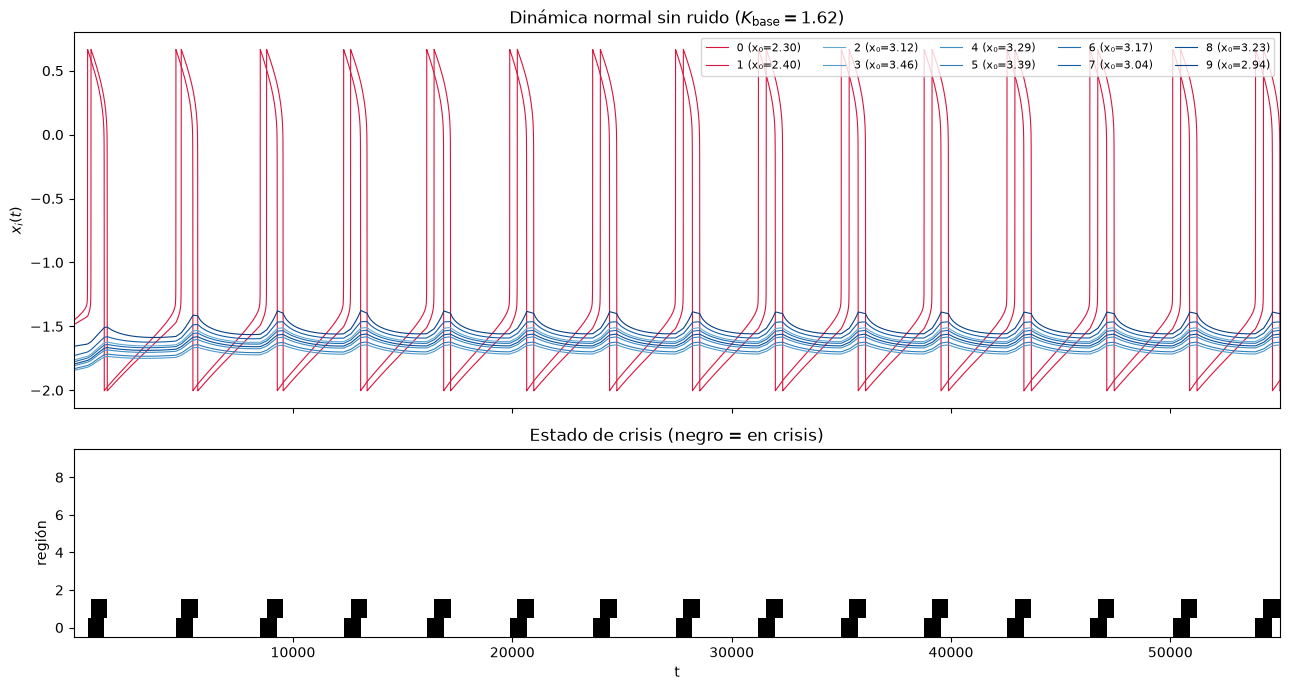

In [13]:
def graficar_series(t, X, S, titulo, archivo, x0_=None):
    x0_ = x0 if x0_ is None else x0_
    fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    for i in range(X.shape[1]):
        ax[0].plot(t, X[:, i], lw=0.8, color="crimson" if x0_[i] < X0_C else plt.cm.Blues(0.4 + 0.06 * i),
                   label=f"{i} (x₀={x0_[i]:.2f})")
    ax[0].set(ylabel="$x_i(t)$", title=titulo)
    ax[0].legend(ncol=5, fontsize=8, loc="upper right")
    ax[1].imshow(S.T, aspect="auto", origin="lower", cmap="Greys", interpolation="nearest",
                 extent=[t[0], t[-1], -0.5, X.shape[1] - 0.5])
    ax[1].set(xlabel="t", ylabel="región", title="Estado de crisis (negro = en crisis)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / archivo, dpi=200)
    plt.show()

det = em_red(x0, A, K_BASE, T=60000, guardar=True, cada=10)
t_det, X_det, S_det = det["t"], det["x"][:, 0, :].astype(float), det["ict"][:, 0, :]
graficar_series(t_det, X_det, S_det, rf"Dinámica normal sin ruido ($K_{{\rm base}}={K_BASE:.2f}$)", "dn_series_sin_ruido.png")

# **2. Matriz de Adyacencia Funcional (sin ruido)**

Como la red estructural es completa, se analiza la **conectividad funcional**:

$$
C_{ij}=\operatorname{corr}\big(x_i(t),\,x_j(t)\big),\qquad
W_{ij}=\max(C_{ij},0),\qquad W_{ii}=0 .
$$

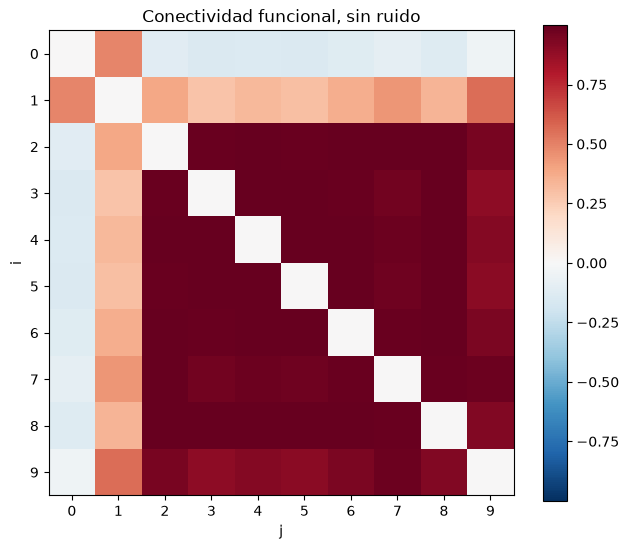

,umbral,n_componentes,componentes
0,0.00,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
1,0.05,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
2,0.10,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
3,0.15,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
4,0.20,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
5,0.25,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
6,0.30,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
7,0.35,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
8,0.40,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"
9,0.45,1,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]"


In [14]:
def matriz_funcional(X):
    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.nan_to_num(np.corrcoef(np.asarray(X, float).T))
    np.fill_diagonal(C, 0.0)
    return C

def grafo_funcional(C, umbral=0.0):
    return nx.from_numpy_array(np.where(C > umbral, C, 0.0))

def graficar_matriz(C, titulo, archivo, ax=None):
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(6.5, 5.5))
    lim = max(np.abs(C).max(), 1e-12)
    im = ax.imshow(C, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(C))); ax.set_yticks(range(len(C)))
    ax.set(xlabel="j", ylabel="i", title=titulo)
    plt.colorbar(im, ax=ax)
    if propio:
        fig.tight_layout()
        fig.savefig(FIG_DIR / archivo, dpi=200)
        plt.show()

def componentes_vs_umbral(C, umbrales):
    filas = []
    for u in umbrales:
        comps = sorted(nx.connected_components(grafo_funcional(C, u)), key=min)
        filas.append({"umbral": u, "n_componentes": len(comps), "componentes": [sorted(c) for c in comps]})
    return pd.DataFrame(filas)

C_det = matriz_funcional(X_det)
graficar_matriz(C_det, "Conectividad funcional, sin ruido", "dn_fc_sin_ruido.png")
display(componentes_vs_umbral(C_det, np.round(np.arange(0.0, 0.61, 0.05), 2)))

## **Detección de comunidades (métodos clásicos)**

| Método | Idea |
|---|---|
| **Louvain** | Maximiza la modularidad $Q$ de forma voraz y jerárquica. |
| **Greedy (CNM)** | Fusiona comunidades de a pares mientras $Q$ aumente. |
| **Propagación de etiquetas** | Cada nodo adopta la etiqueta de mayor peso entre sus vecinos. |
| **Espectral** | Autovectores del laplaciano normalizado más k-medias; el número de comunidades sale de la brecha espectral. |

Cada partición se evalúa con la modularidad $Q$ y con el **ARI** respecto de la partición {foco efectivo, resto}.

In [15]:
def espectral(G, k=None, seed=SEED):
    W = nx.to_numpy_array(G, weight="weight")
    d = W.sum(1).clip(1e-12)
    L = np.eye(len(W)) - W / np.sqrt(np.outer(d, d))
    val, vec = np.linalg.eigh(L)
    if k is None:
        k = max(2, int(np.argmax(np.diff(val[:len(W) // 2 + 1]))) + 1)
    U = vec[:, :k]
    U = U / np.linalg.norm(U, axis=1, keepdims=True).clip(1e-12)
    _, lab = kmeans2(U, k, minit="++", seed=seed)
    return [set(np.where(lab == c)[0]) for c in np.unique(lab)]

def etiquetas(particion, N):
    lab = np.empty(N, int)
    for k, c in enumerate(particion):
        lab[list(c)] = k
    return lab

def ari(part_a, part_b, N):
    tabla = pd.crosstab(etiquetas(part_a, N), etiquetas(part_b, N)).values
    s = comb(tabla, 2).sum()
    a, b = comb(tabla.sum(1), 2).sum(), comb(tabla.sum(0), 2).sum()
    esperado = a * b / comb(N, 2)
    maximo = (a + b) / 2
    return 1.0 if maximo == esperado else (s - esperado) / (maximo - esperado)

PARTICION_REF = [set(np.where(FOCO_EF)[0]), set(np.where(~FOCO_EF)[0])]

def louvain_q_ari(C, seed=SEED):
    G_ = grafo_funcional(C)
    if G_.size(weight="weight") == 0:
        return np.nan, np.nan, [{i} for i in range(len(C))]
    p = louvain_communities(G_, weight="weight", seed=seed)
    return modularity(G_, p, weight="weight"), ari(p, PARTICION_REF, len(C)), p

def detectar_comunidades(C, seed=SEED):
    G_ = grafo_funcional(C)
    metodos = {
        "Louvain": lambda: louvain_communities(G_, weight="weight", seed=seed),
        "Greedy (CNM)": lambda: greedy_modularity_communities(G_, weight="weight"),
        "Propagación de etiquetas": lambda: list(asyn_lpa_communities(G_, weight="weight", seed=seed)),
        "Espectral": lambda: espectral(G_, seed=seed),
    }
    filas, particiones = [], {}
    for nombre, f in metodos.items():
        p = sorted((set(c) for c in f()), key=min)
        particiones[nombre] = p
        filas.append({"método": nombre, "comunidades": [sorted(c) for c in p],
                      "Q": modularity(G_, p, weight="weight"), "ARI vs {foco ef., resto}": ari(p, PARTICION_REF, N)})
    return pd.DataFrame(filas), particiones

tabla_com_det, part_det = detectar_comunidades(C_det)
display(tabla_com_det)

,método,comunidades,Q,"ARI vs {foco ef., resto}"
0,Louvain,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.023492,0.592145
1,Greedy (CNM),"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.023492,0.592145
2,Propagación de etiquetas,"[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]]",0.000000,0.000000
3,Espectral,"[[0, 1], [2, 3, 4, 5, 6, 7, 8, 9]]",0.023492,0.592145


## **¿Qué comunidades están en crisis?**

Una comunidad está **en crisis** en el instante $t$ si más de la mitad de sus miembros está en crisis.

In [16]:
UMBRAL_COMUNIDAD = 0.5

def fraccion_en_crisis(S, comunidades):
    return np.column_stack([S[:, sorted(c)].mean(1) for c in comunidades])

def tabla_crisis(S, comunidades):
    F = fraccion_en_crisis(S, comunidades)
    filas = []
    for k, c in enumerate(comunidades):
        m = sorted(c)
        filas.append({"comunidad": k, "miembros": m, "regiones del foco efectivo": int(FOCO_EF[m].sum()),
                      "x0 medio": x0[m].mean(), "duty medio de sus regiones": S[:, m].mean(),
                      "fracción del tiempo en crisis": (F[:, k] > UMBRAL_COMUNIDAD).mean()})
    return pd.DataFrame(filas)

display(tabla_crisis(S_det, part_det["Louvain"]))

,comunidad,miembros,regiones del foco efectivo,x0 medio,duty medio de sus regiones,fracción del tiempo en crisis
0,0,"[0, 1]",2,2.350000,0.207291,0.121
1,1,"[2, 3, 4, 5, 6, 7, 8, 9]",1,3.203993,0.000000,0.000


**Observaciones.**
- Sin ruido, Louvain, CNM y el método espectral separan $\{0,1\}$ de $\{2,\dots,9\}$; la propagación de etiquetas no separa nada.
- La separación es débil: $Q=0.023$. El grafo funcional es una sola componente hasta un umbral de 0.45.
- Con $K_{\rm base}$ y sin ruido, la región 9 todavía no tiene crisis, por eso queda con las sanas (ARI = 0.59 respecto del foco efectivo).
- **Comunidad en crisis:** $\{0,1\}$ pasa 12.1 % del tiempo en crisis; la comunidad sana, 0 %.

# **3. Ruido como Mecanismo de Crisis**

## **3.1 Una realización con ruido**

(1 s)   crisis por región: [40 40  2  2  2  2  2  3  2 11]


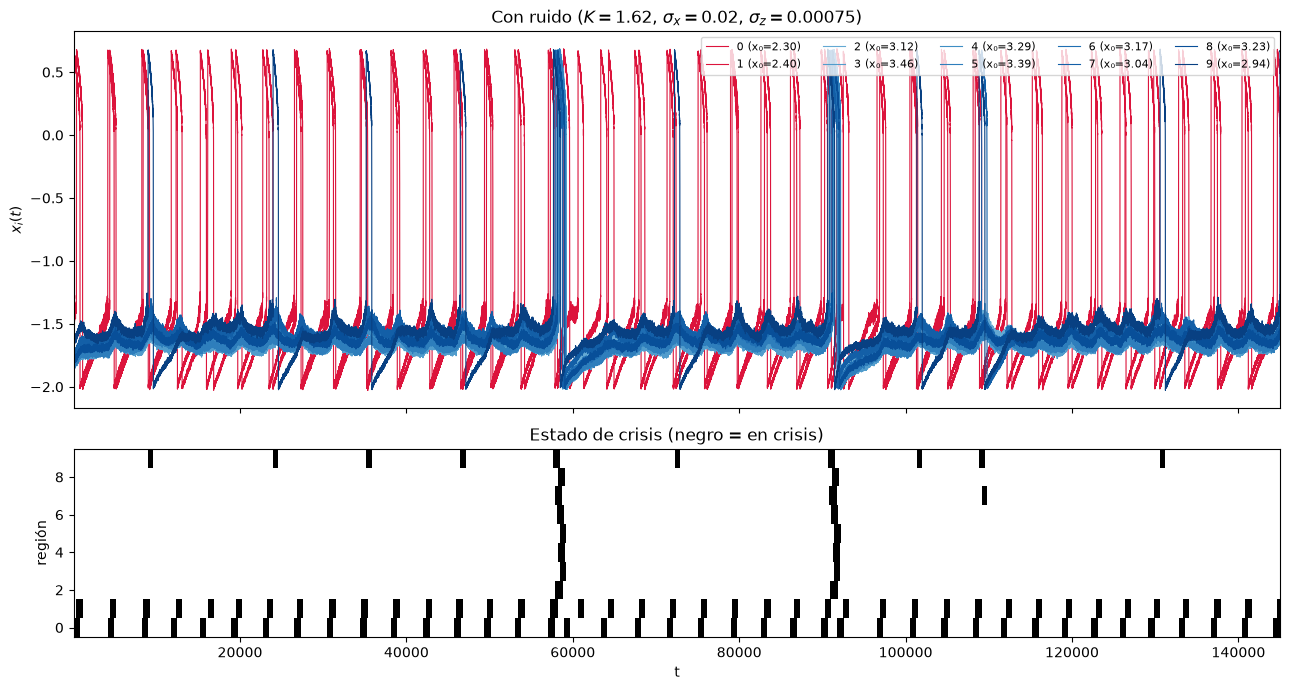

In [17]:
t0 = time.time()
rui = em_red(x0, A, K_BASE, SX, SZ_BASE, T=150000, seed=7, guardar=True, cada=10, foco_mask=FOCO_EF)
t_rui, X_rui, S_rui = rui["t"], rui["x"][:, 0, :].astype(float), rui["ict"][:, 0, :]
print(f"({time.time() - t0:.0f} s)   crisis por región:", rui["n_on"][0])
graficar_series(t_rui, X_rui, S_rui, rf"Con ruido ($K={K_BASE:.2f}$, $\sigma_x={SX}$, $\sigma_z={SZ_BASE}$)",
                "dn_series_con_ruido.png")

## **3.2 Reclutamiento: control $K=0$ vs $K_{\rm base}$ (A4, A6)**

Se comparan condiciones de ruido con $(\sigma_x,\sigma_z)$ explícitos, incluido el caso determinista $(0,0)$, y $R=30$ realizaciones por condición. El **índice de enganche** respecto del foco efectivo es

$$
E=\frac{P(\text{una crisis fuera del foco efectivo empieza con el foco efectivo en crisis})}{\text{fracción del tiempo con el foco efectivo en crisis}} .
$$

$E\approx1$ indica crisis independientes del foco y $E>1$ que el foco las recluta. Los intervalos de confianza del 95 % son por bootstrap sobre realizaciones.

(25 s)


,K,σx,σz,crisis fuera del foco ef./realización,P(crisis) media fuera del foco ef.,IC P,E,IC E,realizaciones con E definido
0,0.00,0.00,0.000000,0.000000,0.000000,"[0.0, 0.0]",NaN,"[nan, nan]",0
1,0.00,0.02,0.000000,0.000000,0.000000,"[0.0, 0.0]",NaN,"[nan, nan]",0
2,0.00,0.02,0.000375,0.000000,0.000000,"[0.0, 0.0]",NaN,"[nan, nan]",0
3,0.00,0.02,0.000750,0.000000,0.000000,"[0.0, 0.0]",NaN,"[nan, nan]",0
4,0.00,0.02,0.001500,1.033333,0.109524,"[0.086, 0.133]",1.069020,"[0.75, 1.37]",22
5,1.62,0.00,0.000000,0.000000,0.000000,"[0.0, 0.0]",NaN,"[nan, nan]",0
6,1.62,0.02,0.000000,0.066667,0.009524,"[0.0, 0.024]",3.230052,"[3.22, 3.24]",2
7,1.62,0.02,0.000375,2.466667,0.276190,"[0.152, 0.414]",2.593837,"[2.28, 2.88]",19
8,1.62,0.02,0.000750,6.966667,0.700000,"[0.562, 0.838]",2.243260,"[2.02, 2.47]",29
9,1.62,0.02,0.001500,15.066667,0.995238,"[0.986, 1.0]",2.268031,"[2.13, 2.41]",30


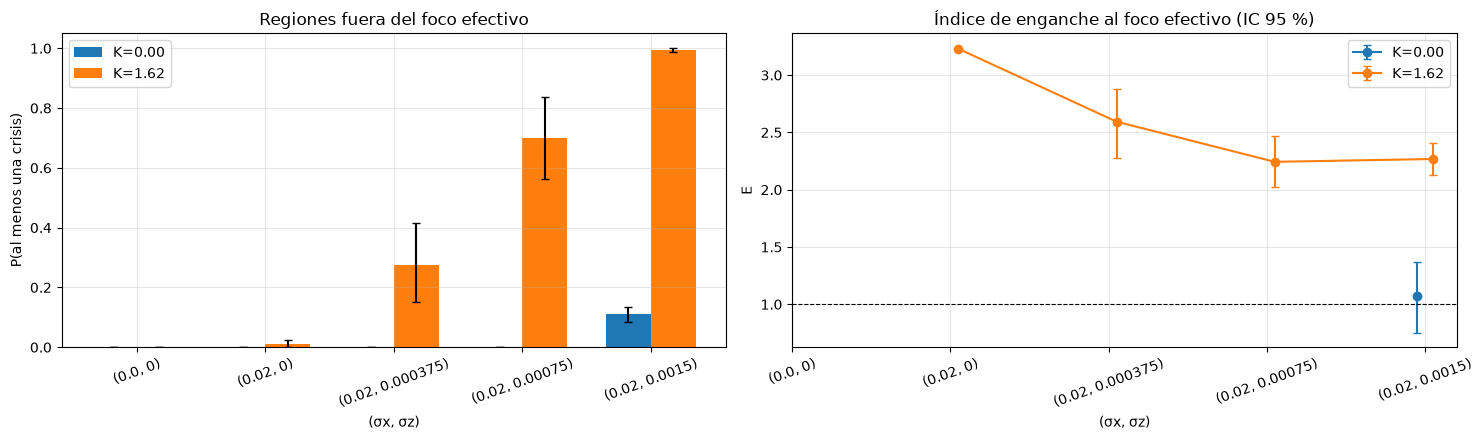

,x0,barrera,P(crisis) K=0,P(crisis) K_BASE
región,,,,
0,2.300,-0.615,1.0,1.000
1,2.400,-0.515,1.0,1.000
2,3.122,0.208,0.0,0.767
3,3.456,0.541,0.0,0.600
4,3.286,0.372,0.0,0.633
5,3.394,0.479,0.0,0.600
6,3.166,0.251,0.0,0.700
7,3.036,0.122,0.0,0.967
8,3.233,0.318,0.0,0.633


In [18]:
def bootstrap_ic(valores, n=2000, seed=SEED, estadistico=np.mean):
    v = np.asarray(valores, float); v = v[np.isfinite(v)]
    if len(v) == 0:
        return np.nan, np.nan
    rng_b = np.random.default_rng(seed)
    b = np.array([estadistico(rng_b.choice(v, len(v))) for _ in range(n)])
    return np.percentile(b, 2.5), np.percentile(b, 97.5)

RESTO = ~FOCO_EF
CONDICIONES = [(0.0, 0.0), (SX, 0.0), (SX, SZ_BASE / 2), (SX, SZ_BASE), (SX, 2 * SZ_BASE)]
K_CONTROL = np.array([0.0, K_BASE])

cond = [(K, sx, sz) for K in K_CONTROL for sx, sz in CONDICIONES]
t0 = time.time()
bar = em_red(x0, A, np.repeat([c[0] for c in cond], R), np.repeat([c[1] for c in cond], R),
             np.repeat([c[2] for c in cond], R), T=60000, M=R * len(cond), seed=21, foco_mask=FOCO_EF)
print(f"({time.time() - t0:.0f} s)")

filas = []
for c, (K, sx, sz) in enumerate(cond):
    sl = slice(c * R, (c + 1) * R)
    on = bar["n_on"][sl][:, RESTO].sum(1); onf = bar["n_on_foco"][sl][:, RESTO].sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        E_m = np.where(on > 0, onf / on, np.nan) / bar["duty_foco"][sl]
    P_m = (bar["n_on"][sl][:, RESTO] > 0).mean(1)
    filas.append({"K": round(K, 3), "σx": sx, "σz": sz, "crisis fuera del foco ef./realización": on.mean(),
                  "P(crisis) media fuera del foco ef.": P_m.mean(), "IC P": np.round(bootstrap_ic(P_m), 3),
                  "E": np.nanmean(E_m), "IC E": np.round(bootstrap_ic(E_m), 2),
                  "realizaciones con E definido": int(np.isfinite(E_m).sum())})
tabla_reclut = pd.DataFrame(filas)
display(tabla_reclut)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for kk, K in enumerate(K_CONTROL):
    sub = tabla_reclut[tabla_reclut.K == round(K, 3)]
    etiquetas_c = [f"({sx}, {sz:g})" for sx, sz in zip(sub["σx"], sub["σz"])]
    xs = np.arange(len(sub)) + (kk - 0.5) * 0.35
    lo = np.array([p[0] for p in sub["IC P"]]); hi = np.array([p[1] for p in sub["IC P"]])
    ax[0].bar(xs, sub["P(crisis) media fuera del foco ef."], 0.35, yerr=[sub["P(crisis) media fuera del foco ef."] - lo, hi - sub["P(crisis) media fuera del foco ef."]],
              label=f"K={K:.2f}", capsize=3)
    loE = np.array([p[0] for p in sub["IC E"]]); hiE = np.array([p[1] for p in sub["IC E"]])
    ax[1].errorbar(np.arange(len(sub)) + (kk - 0.5) * 0.1, sub["E"], yerr=[sub["E"] - loE, hiE - sub["E"]],
                   fmt="o-", capsize=3, label=f"K={K:.2f}")
for a in ax:
    a.set_xticks(range(len(CONDICIONES)), etiquetas_c, rotation=20)
    a.set_xlabel("(σx, σz)"); a.grid(alpha=0.3); a.legend()
ax[0].set(ylabel="P(al menos una crisis)", title="Regiones fuera del foco efectivo")
ax[1].axhline(1, color="k", ls="--", lw=0.8)
ax[1].set(ylabel="E", title="Índice de enganche al foco efectivo (IC 95 %)")
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_reclutamiento_control.png", dpi=200)
plt.show()

k_ref = CONDICIONES.index((SX, SZ_BASE))
P_K0 = (bar["n_on"][k_ref * R:(k_ref + 1) * R] > 0).mean(0)
P_KB = (bar["n_on"][(len(CONDICIONES) + k_ref) * R:(len(CONDICIONES) + k_ref + 1) * R] > 0).mean(0)
display(pd.DataFrame({"x0": x0, "barrera": barrera, "P(crisis) K=0": P_K0, "P(crisis) K_BASE": P_KB},
                     index=pd.Index(range(N), name="región")).round(3))

**Observaciones.**
- **Control $K=0$:** hasta $\sigma_z=7.5\times10^{-4}$ no hay **ninguna** crisis fuera del foco efectivo, en 30 realizaciones. Recién con $2\,\sigma_z$ aparecen ~1 crisis por realización, y entonces $E=1.07$ [0.75, 1.37]: independientes del foco, como se espera por azar.
- **Con $K_{\rm base}$:**
  - el caso determinista $(0,0)$ da 0 crisis y $(0.02,0)$ da 0.07;
  - con $\sigma_z/2$ hay 2.5 crisis por realización y $E=2.59$;
  - con $\sigma_z$ base hay 7.0 crisis por realización, $P=0.70$ [0.56, 0.84] y **$E=2.24$ [2.02, 2.47]**.
- Por región, $P(\text{crisis}\mid K_{\rm base})$ baja con la barrera: 0.97 (región 7), 0.77 (2), 0.70 (6), 0.63 (4 y 8) y 0.60 (3 y 5).
- **El ruido dispara y la red recluta:** ninguno de los dos basta por separado.

## **3.3 Orden de reclutamiento (A5)**

El orden en que entran las regiones lo fija la **barrera**. El efecto de la red se mide con el cociente

$$
\frac{\bar t_{1}(K=0)}{\bar t_{1}(K_{\rm base})}=\frac{\lambda(K_{\rm base})}{\lambda(K=0)},
$$

donde $\lambda$ es la tasa de primera crisis, estimada con censura: número de realizaciones con crisis dividido por el tiempo total de exposición, contando $T$ en las realizaciones sin crisis. Si con $K=0$ no hay ninguna crisis, se usa la cota superior al 95 % $\lambda_0\le3/\text{exposición}$, y el cociente queda como **cota inferior**.

,x0,barrera,t1 medio K_BASE (censurado),crisis K=0 (de R),crisis K_BASE (de R),cociente t1(K=0)/t1(K_BASE),es cota inferior
región,,,,,,,
9,2.94,0.02,8756.50,30,30,1.43,False
7,3.04,0.12,22196.75,0,29,24.78,True
2,3.12,0.21,38885.90,0,23,14.14,True
6,3.17,0.25,48922.20,0,21,11.24,True
8,3.23,0.32,57979.45,0,19,9.49,True
4,3.29,0.37,60337.00,0,19,9.12,True
5,3.39,0.48,67031.35,0,18,8.21,True
3,3.46,0.54,68317.53,0,18,8.05,True


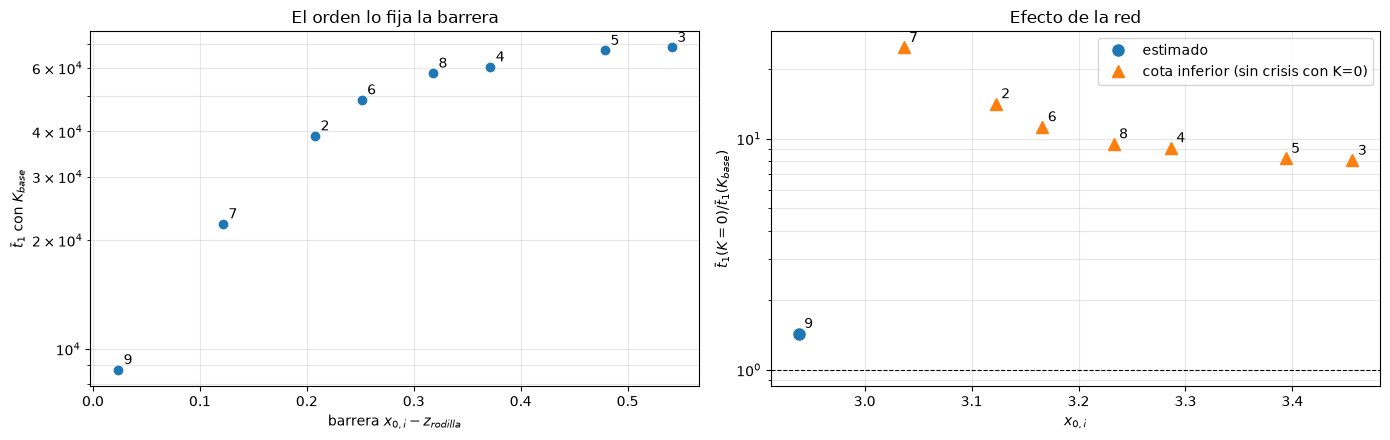

In [19]:
def tasa_primera_crisis(t_first, T_ef):
    hubo = np.isfinite(t_first)
    return hubo.sum(0), np.where(hubo, t_first, T_ef).sum(0)

sl0 = slice(k_ref * R, (k_ref + 1) * R)
slB = slice((len(CONDICIONES) + k_ref) * R, (len(CONDICIONES) + k_ref + 1) * R)
n0, e0 = tasa_primera_crisis(bar["t_first"][sl0], bar["T_ef"])
nB, eB = tasa_primera_crisis(bar["t_first"][slB], bar["T_ef"])
lam0 = np.where(n0 > 0, n0 / e0, 3.0 / e0)
lamB = nB / eB
cociente = lamB / lam0
es_cota = n0 == 0

tabla_orden = pd.DataFrame({"x0": x0, "barrera": barrera, "t1 medio K_BASE (censurado)": 1 / np.where(lamB > 0, lamB, np.nan),
                            "crisis K=0 (de R)": n0, "crisis K_BASE (de R)": nB,
                            "cociente t1(K=0)/t1(K_BASE)": cociente, "es cota inferior": es_cota},
                           index=pd.Index(range(N), name="región"))
display(tabla_orden[RESTO | ZONA_UMBRAL].sort_values("x0").round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
m = sanas & (nB > 0)
ax[0].plot(barrera[m], 1 / lamB[m], "o")
for i in np.where(m)[0]:
    ax[0].annotate(str(i), (barrera[i], 1 / lamB[i]), xytext=(4, 4), textcoords="offset points")
ax[0].set(xlabel="barrera $x_{0,i}-z_{rodilla}$", ylabel=r"$\bar t_1$ con $K_{base}$", yscale="log",
          title="El orden lo fija la barrera")
for marca, sel, lab in [("o", m & ~es_cota, "estimado"), ("^", m & es_cota, "cota inferior (sin crisis con K=0)")]:
    ax[1].plot(x0[sel], cociente[sel], marca, ms=8, label=lab)
for i in np.where(m)[0]:
    ax[1].annotate(str(i), (x0[i], cociente[i]), xytext=(4, 4), textcoords="offset points")
ax[1].axhline(1, color="k", ls="--", lw=0.8)
ax[1].set(xlabel="$x_{0,i}$", ylabel=r"$\bar t_1(K=0)/\bar t_1(K_{base})$", yscale="log", title="Efecto de la red")
ax[1].legend()
for a in ax:
    a.grid(alpha=0.3, which="both")
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_orden_reclutamiento.png", dpi=200)
plt.show()

**Observaciones.**
- El tiempo medio a la primera crisis con $K_{\rm base}$ crece de forma monótona con la barrera: $8.8\times10^3$ (región 9), $2.2\times10^4$ (7), $3.9\times10^4$ (2), $4.9\times10^4$ (6), $5.8\times10^4$ (8), $6.0\times10^4$ (4), $6.7\times10^4$ (5) y $6.8\times10^4$ (3). **El orden lo fija la barrera.**
- El efecto de la red se mide con el cociente $\bar t_1(K=0)/\bar t_1(K_{\rm base})$:
  - para la región 9 es apenas 1.4, porque ya tiene crisis sola;
  - para las demás es **≥ 8–25**. Es una cota inferior, porque con $K=0$ nunca entran en crisis.
- El efecto de la red es máximo en la región 7 (≥ 25) y decrece al alejarse del umbral.

## **3.4 Simulación con series guardadas**

Para los análisis de dirección (B7, B8) y de conectividad funcional (B9, B10) se guardan las series de $R=30$ realizaciones con $K=0$ y con $K_{\rm base}$ ($T=10^5$).

In [20]:
def inicios(S, t):
    on = S[1:] & ~S[:-1]
    return [t[1:][on[:, i]] for i in range(S.shape[1])]

t0 = time.time()
nul = em_red(x0, A, np.repeat(K_CONTROL, R), SX, SZ_BASE, T=100000, M=len(K_CONTROL) * R, seed=33,
             guardar=True, cada=20, foco_mask=FOCO_EF)
T_NUL = nul["t"][-1]
ev_nul = [inicios(nul["ict"][:, m, :], nul["t"]) for m in range(len(K_CONTROL) * R)]
print(f"({time.time() - t0:.0f} s)")

(11 s)


## **B7. Dirección del reclutamiento: retrasos**

Para cada inicio de crisis fuera del foco efectivo, se mide el tiempo desde el inicio **más reciente** de una crisis del disparador, ya sea el foco $\{0,1\}$ o el foco efectivo. Si el foco recluta, los retrasos deben ser positivos y concentrados; si no, difusos.

,K,disparador,n inicios,mediana,P10–P90
0,0.00,"foco {0,1}",0,NaN,None
1,0.00,foco efectivo,0,NaN,None
2,1.62,"foco {0,1}",391,934.0,"[636.0, 1324.0]"
3,1.62,foco efectivo,391,548.0,"[230.0, 912.0]"


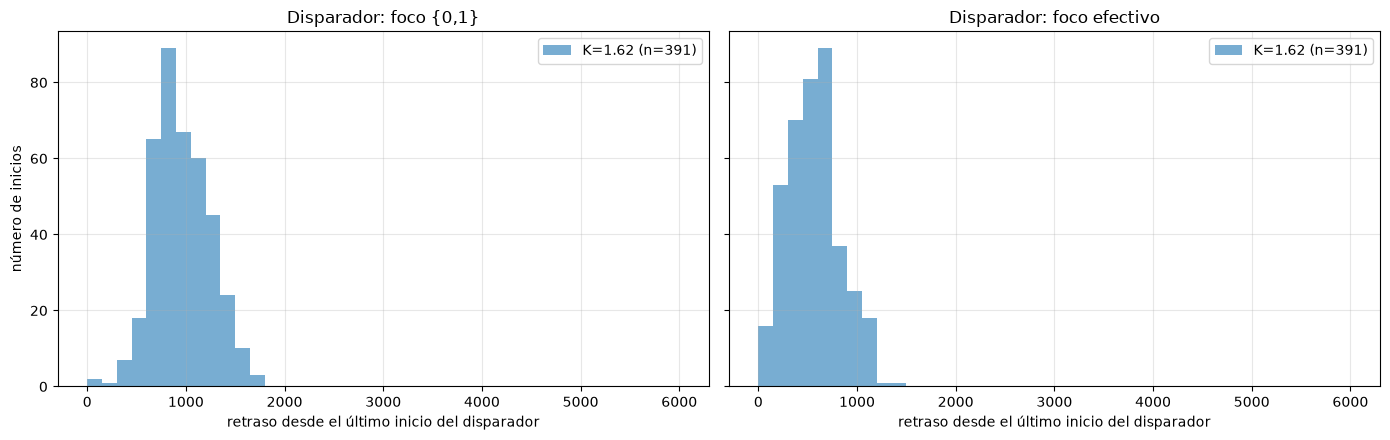

In [21]:
def retrasos(ev_resp, ev_disp):
    if len(ev_disp) == 0 or len(ev_resp) == 0:
        return np.array([])
    k = np.searchsorted(ev_disp, ev_resp, side="right") - 1
    return (ev_resp - ev_disp[np.clip(k, 0, None)])[k >= 0]

disparadores = {"foco {0,1}": np.where(foco)[0], "foco efectivo": np.where(FOCO_EF)[0]}
ret = {}
for kk, K in enumerate(K_CONTROL):
    for nombre, idx in disparadores.items():
        d = []
        for m in range(kk * R, (kk + 1) * R):
            ev = ev_nul[m]
            f = np.sort(np.concatenate([ev[j] for j in idx]))
            for i in np.where(RESTO)[0]:
                d.append(retrasos(ev[i], f))
        ret[(K, nombre)] = np.concatenate(d) if d else np.array([])

filas = []
for (K, nombre), d in ret.items():
    filas.append({"K": round(K, 3), "disparador": nombre, "n inicios": len(d),
                  "mediana": np.median(d) if len(d) else np.nan,
                  "P10–P90": np.round(np.percentile(d, [10, 90]), 0) if len(d) else None})
display(pd.DataFrame(filas))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for a, nombre in zip(ax, disparadores):
    for K in K_CONTROL:
        d = ret[(K, nombre)]
        if len(d):
            a.hist(d, bins=np.linspace(0, 6000, 41), alpha=0.6, label=f"K={K:.2f} (n={len(d)})")
    a.set(xlabel="retraso desde el último inicio del disparador", title=f"Disparador: {nombre}")
    a.legend(); a.grid(alpha=0.3)
ax[0].set_ylabel("número de inicios")
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_retrasos.png", dpi=200)
plt.show()

**Observaciones.**
- Con $K=0$ no hay ningún inicio fuera del foco efectivo. Con $K_{\rm base}$ hay 391, todos con retrasos **positivos y concentrados**:
  - desde el foco efectivo: mediana 548, con P10–P90 = [230, 912];
  - desde $\{0,1\}$: mediana 934, con P10–P90 = [636, 1324].
- Que los retrasos sean más cortos desde el foco efectivo indica que el disparador inmediato de las regiones sanas es la región 9. A su vez, la 9 es arrastrada por $\{0,1\}$.

## **B8. Grafo dirigido funcional vs DAG**

$$
R_{ij}=P\big(\text{un inicio de } i \in (t_j,\,t_j+w]\ \big|\ \text{inicio de } j \text{ en } t_j\big)-\big(1-e^{-\lambda_i w}\big),
$$

con $\lambda_i$ la tasa de inicios de $i$. El término restado es la probabilidad de que $i$ empiece una crisis al azar dentro de la ventana (proceso de Poisson). Por eso depende de la tasa de la región que **responde**, $\lambda_i$. **Convención:** $R_{ij}>0$ significa que $j$ empuja a $i$.

El DAG del notebook anterior es $A^{\rm DAG}_{ij}=1\iff x_{0,j}<x_{0,i}$ ($j$ más excitable empuja a $i$). El **acuerdo** es la fracción de pares $i<j$ (sin empates) en que $\operatorname{sign}(R-R^T)_{ij}$ coincide con el DAG.

In [22]:
A_DAG = (x0[None, :] < x0[:, None])

def grafo_reclutamiento(ev, T, ventana):
    n = len(ev)
    Rm = np.zeros((n, n))
    lam = np.array([len(e) / T for e in ev])
    for j in range(n):
        if len(ev[j]) == 0:
            continue
        for i in range(n):
            if i == j or len(ev[i]) == 0:
                continue
            k = np.searchsorted(ev[i], ev[j], side="right")
            dentro = (k < len(ev[i])) & (ev[i][np.clip(k, 0, len(ev[i]) - 1)] - ev[j] <= ventana)
            Rm[i, j] = dentro.mean() - (1 - np.exp(-lam[i] * ventana))
    return Rm

def acuerdo_con_dag(Rm, A_dag=None):
    A_dag = A_DAG if A_dag is None else A_dag
    D = np.sign(Rm - Rm.T)
    iu = np.triu_indices(len(Rm), 1)
    d, a = D[iu], np.where(A_dag[iu], 1, -1)
    m = d != 0
    return ((d[m] == a[m]).mean() if m.any() else np.nan), int(m.sum())

VENTANAS = [1000, 1500, 2500]
filas, R_medio = [], {}
for w in VENTANAS:
    for kk, K in enumerate(K_CONTROL):
        Rs = [grafo_reclutamiento(ev_nul[m], T_NUL, w) for m in range(kk * R, (kk + 1) * R)]
        ac = np.array([acuerdo_con_dag(Rm)[0] for Rm in Rs])
        pares = np.mean([acuerdo_con_dag(Rm)[1] for Rm in Rs])
        R_medio[(w, K)] = np.mean(Rs, axis=0)
        filas.append({"ventana": w, "K": round(K, 3), "acuerdo medio": np.nanmean(ac),
                      "IC 95 %": np.round(bootstrap_ic(ac), 3), "pares sin empate / realización": pares})
tabla_dag = pd.DataFrame(filas)
display(tabla_dag)

,ventana,K,acuerdo medio,IC 95 %,pares sin empate / realización
0,1000,0.00,0.588889,"[0.489, 0.689]",3.000000
1,1000,1.62,0.805961,"[0.774, 0.84]",38.533333
2,1500,0.00,0.577778,"[0.5, 0.656]",3.000000
3,1500,1.62,0.783838,"[0.745, 0.825]",38.633333
4,2500,0.00,0.522222,"[0.422, 0.622]",3.000000
5,2500,1.62,0.774562,"[0.738, 0.812]",38.666667


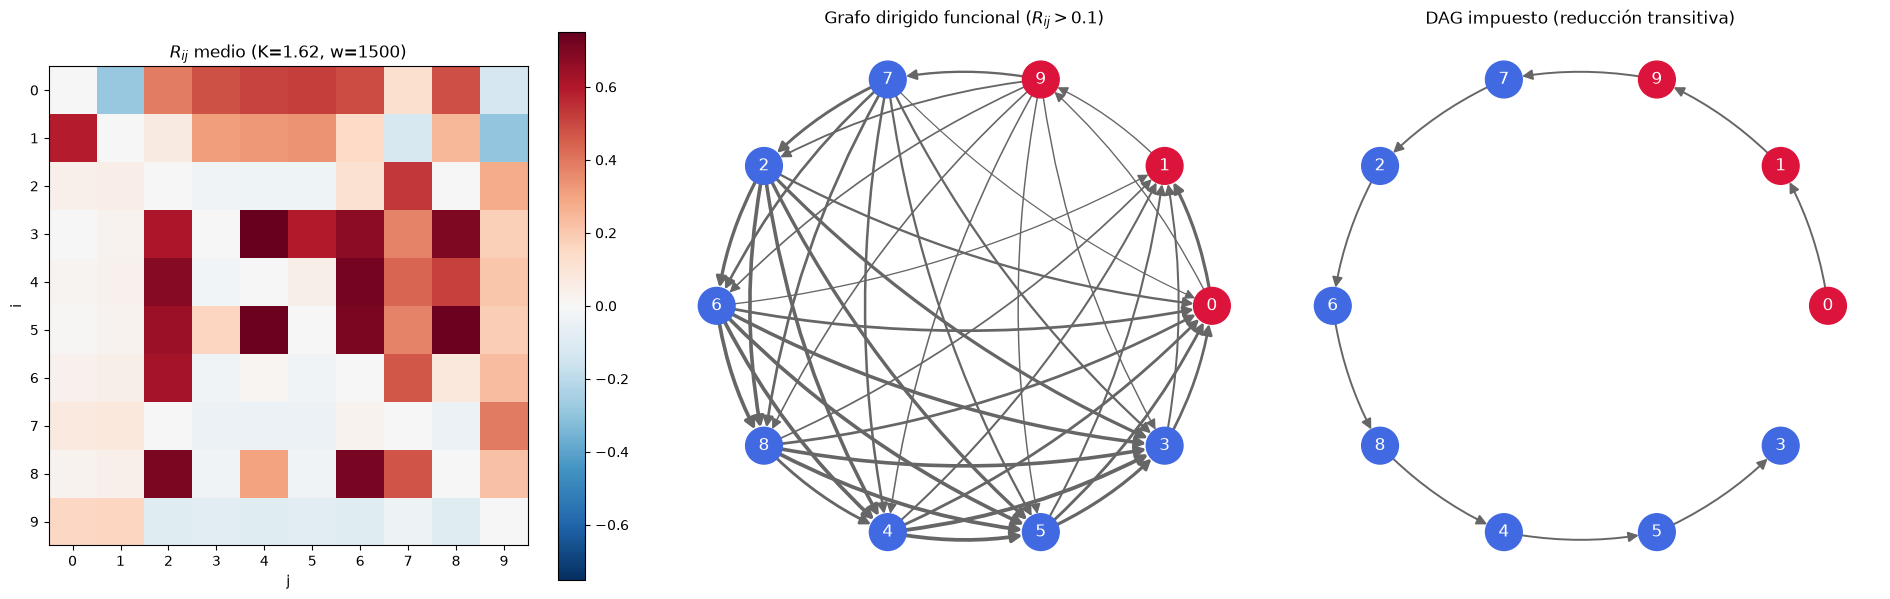

In [23]:
W_DIB = 1500
Rm = R_medio[(W_DIB, K_BASE)]
orden_x0 = np.argsort(x0)
pos_orden = {int(n): (np.cos(2 * np.pi * k / N), np.sin(2 * np.pi * k / N)) for k, n in enumerate(orden_x0)}

G_dag = nx.transitive_reduction(nx.DiGraph(A_DAG.T.astype(int)))
G_fun = nx.DiGraph()
G_fun.add_nodes_from(range(N))
for i in range(N):
    for j in range(N):
        if Rm[i, j] > 0.1 and Rm[i, j] > Rm[j, i]:
            G_fun.add_edge(j, i, weight=Rm[i, j])

fig, ax = plt.subplots(1, 3, figsize=(19, 6))
graficar_matriz(Rm, f"$R_{{ij}}$ medio (K={K_BASE:.2f}, w={W_DIB})", None, ax=ax[0])
for a, Gd, titulo in [(ax[1], G_fun, "Grafo dirigido funcional ($R_{ij}>0.1$)"),
                      (ax[2], G_dag, "DAG impuesto (reducción transitiva)")]:
    pesos = [3 * Gd[u][v].get("weight", 0.3) + 0.5 for u, v in Gd.edges()]
    nx.draw_networkx(Gd, pos=pos_orden, ax=a, node_color=np.where(FOCO_EF, "crimson", "royalblue"),
                     node_size=700, font_color="white", width=pesos, arrowsize=15, edge_color="0.4",
                     connectionstyle="arc3,rad=0.1")
    a.set_title(titulo); a.axis("off")
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_grafo_funcional_vs_dag.png", dpi=200)
plt.show()

**Observaciones.**
- Con $K_{\rm base}$, el acuerdo con el DAG es **0.81** [0.77, 0.84] con $w=1000$, 0.78 con $w=1500$ y 0.77 con $w=2500$.
- Con $K=0$ es 0.52–0.59, pero solo hay 3 pares comparables, porque solo $\{0,1,9\}$ tienen crisis.
- El grafo funcional reproduce la cadena del DAG: $9\to7\to2\to6\to8\to4\to5\to3$.
- La diferencia con el DAG son las **aristas de retorno sanas → foco** (fila 0 de $R_{ij}$): el nodo 0 empieza una crisis poco después de una cascada sana. Ese efecto no existe en el DAG, donde el nodo 0 no recibe nada (ver B11).

## **B10. Modelo nulo con surrogados**

Cada surrogado desplaza circularmente, de forma aleatoria e independiente, la serie de inicios de cada región. Así se conserva el número de crisis y su estadística temporal propia, pero se destruye la relación temporal **entre** regiones. Con 200 surrogados se construye la distribución nula del acuerdo con el DAG (sobre el $R_{ij}$ promedio) y de la modularidad $Q$ de la conectividad funcional.

(13 s)
Acuerdo con el DAG: observado = 0.711; surrogados = 0.415 ± 0.065; p = 0.0050
Q de Louvain:       observado = 0.084; surrogados = 0.347 ± 0.124; p = 0.9851


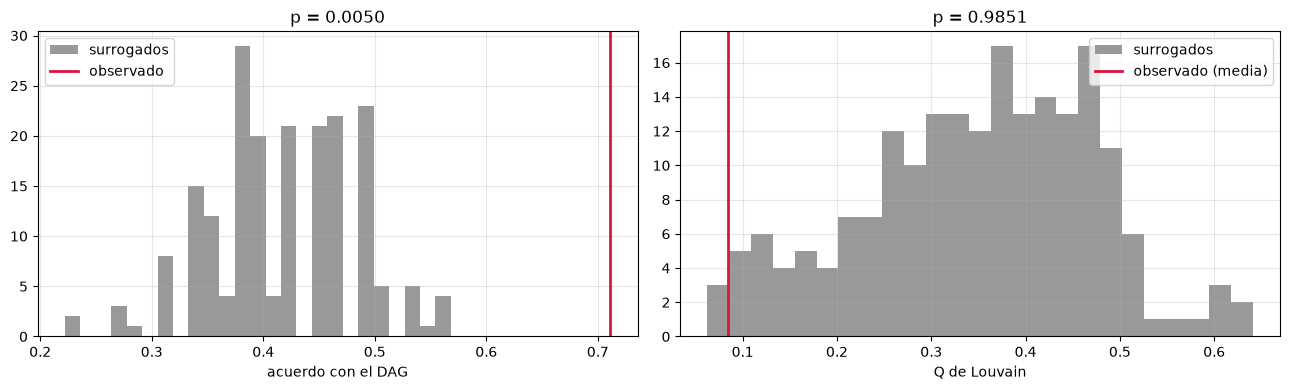

In [24]:
N_SUR = 200
rng_s = np.random.default_rng(SEED)

def desplazar(ev, T, rng_):
    return [np.sort((e + rng_.uniform(0, T)) % T) for e in ev]

idx_B = range(R, 2 * R)
ac_obs = acuerdo_con_dag(np.mean([grafo_reclutamiento(ev_nul[m], T_NUL, W_DIB) for m in idx_B], axis=0))[0]
t0 = time.time()
ac_sur = np.array([acuerdo_con_dag(np.mean([grafo_reclutamiento(desplazar(ev_nul[m], T_NUL, rng_s), T_NUL, W_DIB)
                                            for m in idx_B], axis=0))[0] for _ in range(N_SUR)])
p_dag = (np.sum(ac_sur >= ac_obs) + 1) / (N_SUR + 1)

Q_obs = np.array([louvain_q_ari(matriz_funcional(nul["x"][:, m, :]))[0] for m in idx_B])
Q_sur = []
for s in range(N_SUR):
    Xm = nul["x"][:, R + s % R, :].astype(float)
    Xs = np.column_stack([np.roll(Xm[:, i], rng_s.integers(len(Xm))) for i in range(N)])
    Q_sur.append(louvain_q_ari(matriz_funcional(Xs))[0])
Q_sur = np.array(Q_sur)
p_Q = (np.sum(Q_sur >= Q_obs.mean()) + 1) / (N_SUR + 1)
print(f"({time.time() - t0:.0f} s)")
print(f"Acuerdo con el DAG: observado = {ac_obs:.3f}; surrogados = {np.nanmean(ac_sur):.3f} ± {np.nanstd(ac_sur):.3f}; p = {p_dag:.4f}")
print(f"Q de Louvain:       observado = {Q_obs.mean():.3f}; surrogados = {Q_sur.mean():.3f} ± {Q_sur.std():.3f}; p = {p_Q:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(ac_sur, bins=25, color="0.6", label="surrogados"); ax[0].axvline(ac_obs, color="crimson", lw=2, label="observado")
ax[0].set(xlabel="acuerdo con el DAG", title=f"p = {p_dag:.4f}")
ax[1].hist(Q_sur, bins=25, color="0.6", label="surrogados"); ax[1].axvline(Q_obs.mean(), color="crimson", lw=2, label="observado (media)")
ax[1].set(xlabel="Q de Louvain", title=f"p = {p_Q:.4f}")
for a in ax:
    a.legend(); a.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_surrogados.png", dpi=200)
plt.show()

**Observaciones.**
- **Acuerdo con el DAG:** observado 0.711, contra 0.415 ± 0.065 en los surrogados, con $p=0.005$ (el mínimo posible con 200 surrogados). La dirección del reclutamiento no se explica por las tasas individuales de crisis.
- **Modularidad:** el $Q$ observado (0.084) es *menor* que el de los surrogados (0.347 ± 0.124; $p=0.985$). El acoplamiento homogeneiza la conectividad funcional en vez de crear módulos.

## **Resultado negativo: modularidad bajo ruido (D19, B9)**

La detección de comunidades por modularidad **no se usa como método principal**. Aquí se documenta por qué: con ruido, $Q$ no distingue la red acoplada del control sin red. Se comparan cuatro medidas de conectividad funcional:

- **corr($x$):** correlación de las series $x_i(t)$;
- **corr(crisis):** correlación de los estados de crisis (0/1);
- **sincronización de eventos:** $Q^{\rm ES}_{ij}=c_{ij}/\sqrt{m_im_j}$, con $c_{ij}$ el número de pares de inicios a menos de $\tau=1000$ y $m_i$ el número de inicios de $i$;
- **corr($z$):** correlación de la variable lenta $z_i(t)$.

,medida,K,Q,IC Q,"ARI vs {foco ef., resto}",IC ARI
0,corr(x),0.00,2.552296e-01,"[0.23, 0.281]",0.026430,"[-0.017, 0.069]"
1,corr(x),1.62,8.442643e-02,"[0.068, 0.103]",0.438078,"[0.365, 0.507]"
2,corr(crisis),0.00,1.281027e-17,"[-0.0, 0.0]",0.078322,"[0.063, 0.093]"
3,corr(crisis),1.62,1.317256e-01,"[0.102, 0.164]",0.345324,"[0.273, 0.421]"
4,sincronización de eventos,0.00,4.440892e-17,"[0.0, 0.0]",0.115025,"[0.11, 0.118]"
5,sincronización de eventos,1.62,7.498924e-02,"[0.061, 0.09]",0.611544,"[0.497, 0.733]"
6,corr(z),0.00,2.403234e-01,"[0.216, 0.267]",0.013296,"[-0.034, 0.065]"
7,corr(z),1.62,1.109452e-01,"[0.092, 0.131]",0.523877,"[0.468, 0.583]"


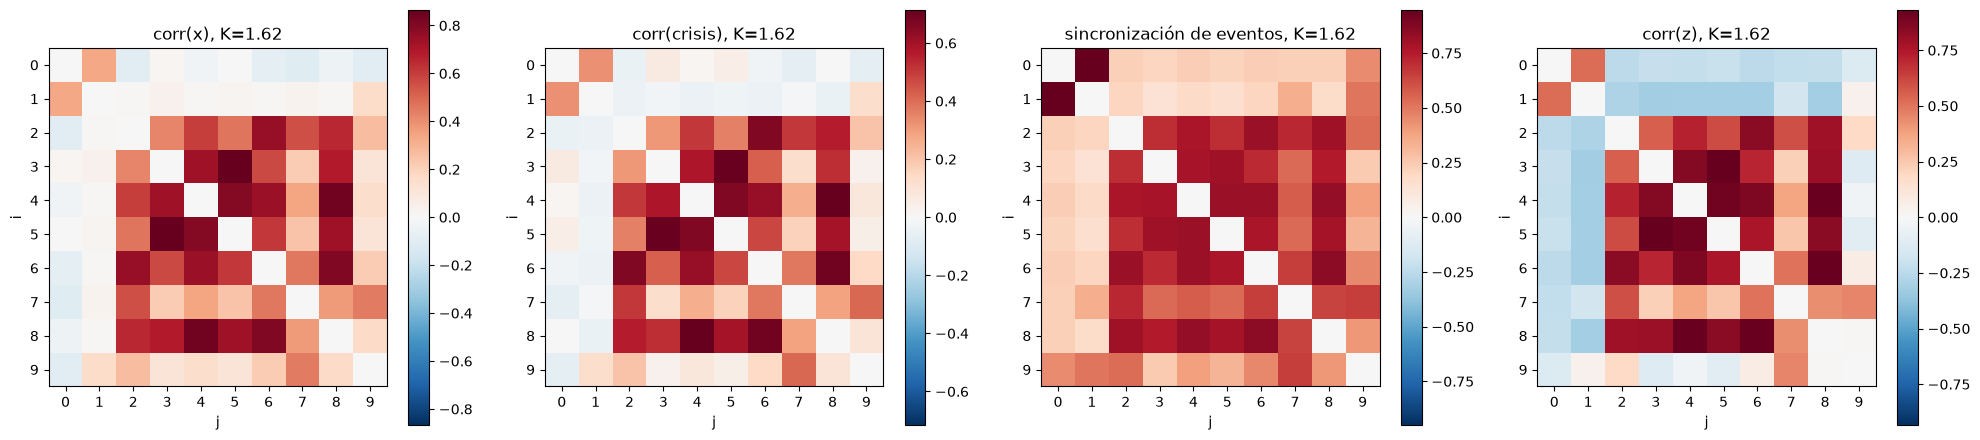

In [25]:
def sincronizacion_eventos(ev, tau=1000.0):
    n = len(ev); Q = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            if len(ev[i]) and len(ev[j]):
                c = (np.abs(ev[i][:, None] - ev[j][None, :]) <= tau).sum()
                Q[i, j] = Q[j, i] = c / np.sqrt(len(ev[i]) * len(ev[j]))
    return Q

MEDIDAS = {
    "corr(x)": lambda m: matriz_funcional(nul["x"][:, m, :]),
    "corr(crisis)": lambda m: matriz_funcional(nul["ict"][:, m, :].astype(float)),
    "sincronización de eventos": lambda m: sincronizacion_eventos(ev_nul[m]),
    "corr(z)": lambda m: matriz_funcional(nul["z"][:, m, :]),
}
filas = []
for nombre, f in MEDIDAS.items():
    for kk, K in enumerate(K_CONTROL):
        qa = np.array([louvain_q_ari(f(m))[:2] for m in range(kk * R, (kk + 1) * R)])
        filas.append({"medida": nombre, "K": round(K, 3), "Q": np.nanmean(qa[:, 0]), "IC Q": np.round(bootstrap_ic(qa[:, 0]), 3),
                      "ARI vs {foco ef., resto}": np.nanmean(qa[:, 1]), "IC ARI": np.round(bootstrap_ic(qa[:, 1]), 3)})
tabla_medidas = pd.DataFrame(filas)
display(tabla_medidas)

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
for a, (nombre, f) in zip(ax, MEDIDAS.items()):
    graficar_matriz(np.mean([f(m) for m in idx_B], axis=0), f"{nombre}, K={K_BASE:.2f}", None, ax=a)
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_medidas_fc.png", dpi=200)
plt.show()

**Observaciones (resultado negativo).**
- Con corr($x$) y corr($z$), $Q$ es **mayor sin red** ($K=0$: 0.26 y 0.24) que con red ($K_{\rm base}$: 0.08 y 0.11). $Q$ mide estructura del ruido, no reclutamiento.
- El ARI respecto de {foco efectivo, resto} sí mejora con el acoplamiento. La mejor medida es la sincronización de eventos (0.61 [0.50, 0.73]), seguida de corr($z$) (0.52).
- Aun así, la partición varía mucho entre realizaciones. Por eso el análisis principal del reclutamiento es dirigido (B7 y B8) y no la modularidad.

# **C13. Predicción analítica del reclutamiento**

En la rama baja la sigmoide vale casi cero, $h\approx x_{0,i}$, y la ecuación de $z_i$ es lineal:

$$
\tau_0\dot z_i=x_{0,i}-z_i-\frac{K}{N}c_i(t),\qquad c_i(t)=\sum_jA_{ij}\big(x_j(t)-x_i(t)\big).
$$

Su solución es $z_i(t)=x_{0,i}-\frac{K}{N}\tilde c_i(t)$, donde $\tilde c_i$ es $c_i$ filtrado con un filtro exponencial de constante $\tau_0$. La región se recluta cuando $\min_t z_i<z_{\rm rodilla}$:

$$
K_{c,i}=\frac{N\,(x_{0,i}-z_{\rm rodilla})}{\max_t\tilde c_i(t)} .
$$

- **Versión de campo medio** (la de la tarea): $\tilde c_i\to\langle c_i\rangle_t$, un $x_0$ efectivo $x_{0,i}^{\rm ef}=x_{0,i}-\frac{K}{N}\langle c_i\rangle$.
- **Versión filtrada:** usa $\max_t\tilde c_i$. Es necesaria porque $\tau_0=2857$ es del orden del período del foco, así que $z$ **no** promedia la oscilación.

$\tilde c_i$ se calcula con las series deterministas a un $K$ subcrítico, sin usar el $K_c$ simulado.

In [26]:
def acople_filtrado(X, W, dt):
    c = X @ W.T - W.sum(1) * X
    a = dt / TAU0
    return c, lfilter([a], [1, -(1 - a)], c, axis=0)

def kc_predicho(x0_, W, K_eval, metodo="filtrado", T=60000):
    n = len(x0_)
    d = em_red(x0_, W, K_eval, T=T, t_trans=0, guardar=True, cada=10)
    X = d["x"][:, 0, :].astype(float)
    c, cf = acople_filtrado(X, W, d["t"][1] - d["t"][0])
    cc = c[len(c) // 4:].mean(0) if metodo == "media" else cf[len(cf) // 4:].max(0)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(cc > 0, n * (x0_ - Z_RODILLA) / cc, np.inf)

def kc_por_region(x0_, W, Ks, T=60000):
    r = em_red(x0_, W, Ks, T=T, M=len(Ks))
    kc = np.array([Ks[np.argmax(r["n_on"][:, i] > 0)] if (r["n_on"][:, i] > 0).any() else np.nan for i in range(len(x0_))])
    return kc, r

K_C13 = np.round(np.linspace(1.5, 2.5, 101), 3)
kc_ec8, _ = kc_por_region(x0, A, K_C13)
tabla_c13 = pd.DataFrame({"x0": x0, "barrera": barrera, "K_c simulado": kc_ec8,
                          "K_c predicho (media)": kc_predicho(x0, A, K_BASE, "media"),
                          "K_c predicho (filtrado)": kc_predicho(x0, A, K_BASE, "filtrado")},
                         index=pd.Index(range(N), name="región"))
display(tabla_c13[sanas].sort_values("x0").round(3))
primera = np.where(sanas)[0][np.nanargmin(kc_ec8[sanas])]
err_red = tabla_c13.loc[primera, "K_c predicho (filtrado)"] / tabla_c13.loc[primera, "K_c simulado"] - 1
print(f"Primera región reclutada: {primera}; error relativo de la predicción filtrada: {100 * err_red:+.1f} %")

,x0,barrera,K_c simulado,K_c predicho (media),K_c predicho (filtrado)
región,,,,,
9,2.938,0.023,1.80,inf,1.718
7,3.036,0.122,1.91,12.295,2.216
2,3.122,0.208,1.91,4.938,2.356
6,3.166,0.251,1.93,4.368,2.416
8,3.233,0.318,1.93,3.960,2.501
4,3.286,0.372,1.93,3.796,2.564
5,3.394,0.479,1.93,3.644,2.681
3,3.456,0.541,1.93,3.609,2.744


Primera región reclutada: 9; error relativo de la predicción filtrada: -4.5 %


## **Dos regiones (N = 2): predicción autoconsistente**

Con un foco ($x_0=2.3$) y una región sana se itera $K_{n+1}=K_c^{\rm pred}(0.95\,K_n)$, partiendo de la predicción con $K=0$. Cada iteración evalúa $\tilde c$ con la simulación determinista justo bajo la predicción anterior, sin usar el $K_c$ simulado.

,x0 sana,K_c simulado,"K_c predicho (media, K=0)",K_c predicho (autoconsistente),error relativo
0,2.920,0.02,0.020,0.011,-0.445
1,2.982,0.15,0.212,0.131,-0.124
2,3.044,0.28,0.370,0.256,-0.085
3,3.105,0.41,0.511,0.384,-0.063
4,3.167,0.55,0.642,0.527,-0.042
5,3.229,0.70,0.765,0.670,-0.043
6,3.291,0.85,0.881,0.816,-0.040
7,3.353,1.01,0.993,0.969,-0.041
8,3.415,1.19,1.100,1.128,-0.052
9,3.476,1.37,1.203,1.294,-0.056


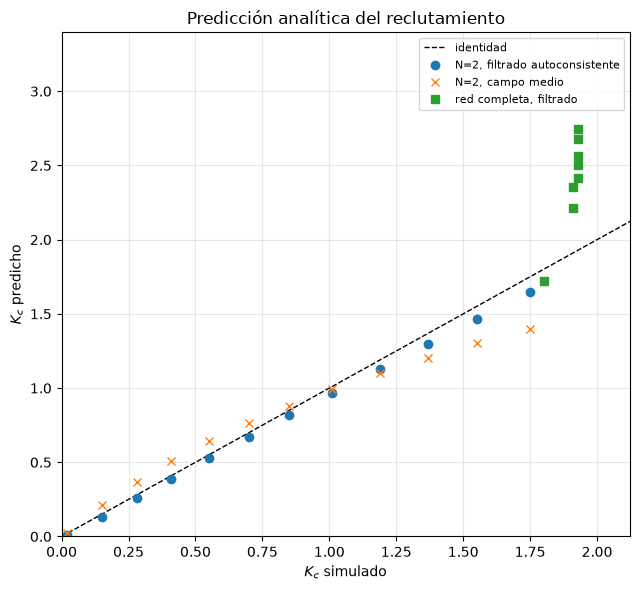

In [27]:
A2 = np.ones((2, 2)) - np.eye(2)
X02_C13 = np.linspace(2.92, 3.6, 12)
K2_FINO = np.linspace(0, 4, 401)

filas = []
for xv in X02_C13:
    x0_2 = np.array([2.3, xv])
    r2 = em_red(x0_2, A2, K2_FINO, T=60000, M=len(K2_FINO))
    k_sim = K2_FINO[np.argmax(r2["n_on"][:, 1] > 0)]
    k_pred = kc_predicho(x0_2, A2, 0.0)[1]
    for _ in range(5):                      # se evalúa justo bajo la predicción anterior
        k_pred = kc_predicho(x0_2, A2, 0.95 * k_pred)[1]
    filas.append({"x0 sana": xv, "K_c simulado": k_sim, "K_c predicho (media, K=0)": kc_predicho(x0_2, A2, 0.0, "media")[1],
                  "K_c predicho (autoconsistente)": k_pred})
tabla_n2 = pd.DataFrame(filas)
tabla_n2["error relativo"] = tabla_n2["K_c predicho (autoconsistente)"] / tabla_n2["K_c simulado"] - 1
display(tabla_n2.round(3))

fig, ax = plt.subplots(figsize=(6.5, 6))
lim = [0, max(tabla_n2["K_c simulado"].max(), tabla_c13["K_c simulado"].max()) * 1.1]
ax.plot(lim, lim, "k--", lw=1, label="identidad")
ax.plot(tabla_n2["K_c simulado"], tabla_n2["K_c predicho (autoconsistente)"], "o", label="N=2, filtrado autoconsistente")
ax.plot(tabla_n2["K_c simulado"], tabla_n2["K_c predicho (media, K=0)"], "x", label="N=2, campo medio")
s = tabla_c13[sanas]
ax.plot(s["K_c simulado"], s["K_c predicho (filtrado)"].clip(upper=lim[1] * 2), "s", label="red completa, filtrado")
ax.set(xlabel="$K_c$ simulado", ylabel="$K_c$ predicho", xlim=lim, ylim=[0, lim[1] * 1.6],
       title="Predicción analítica del reclutamiento")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_prediccion_kc.png", dpi=200)
plt.show()

**Observaciones.**
- **Campo medio (promedio temporal):** falla. Para la región 9 da $\langle c\rangle\le0$ (no predice reclutamiento) y para las demás da $K_c=3.6$–$12$, contra ~1.9 simulado. El promedio borra los picos de acoplamiento durante las crisis del foco.
- **Versión filtrada:** predice $K_c=1.718$ para la región 9, contra 1.800 simulado (**−4.5 %**).
  - Para el resto predice 2.2–2.7, contra 1.91–1.93 simulado. La predicción individual sobreestima porque ignora la **cascada**: una vez reclutada la 9, su crisis empuja a las demás.
- **N = 2:** la predicción autoconsistente acierta con un error de 4–6 %. Se exceptúa $x_0=2.92$, donde $K_c\approx0.02$ y el error relativo pierde sentido. La de campo medio sobreestima a $K$ bajo y subestima hasta un 20 % a $K$ alto.

# **C14. Diagrama de reclutamiento $(x_0^{\rm sana},K)$**

Dos regiones ($N=2$): el foco con $x_0=2.3$ y una región sana con $x_0\in[2.92,\,3.6]$. Se muestra el número de crisis de la región sana y del foco, sin ruido.

(15 s)


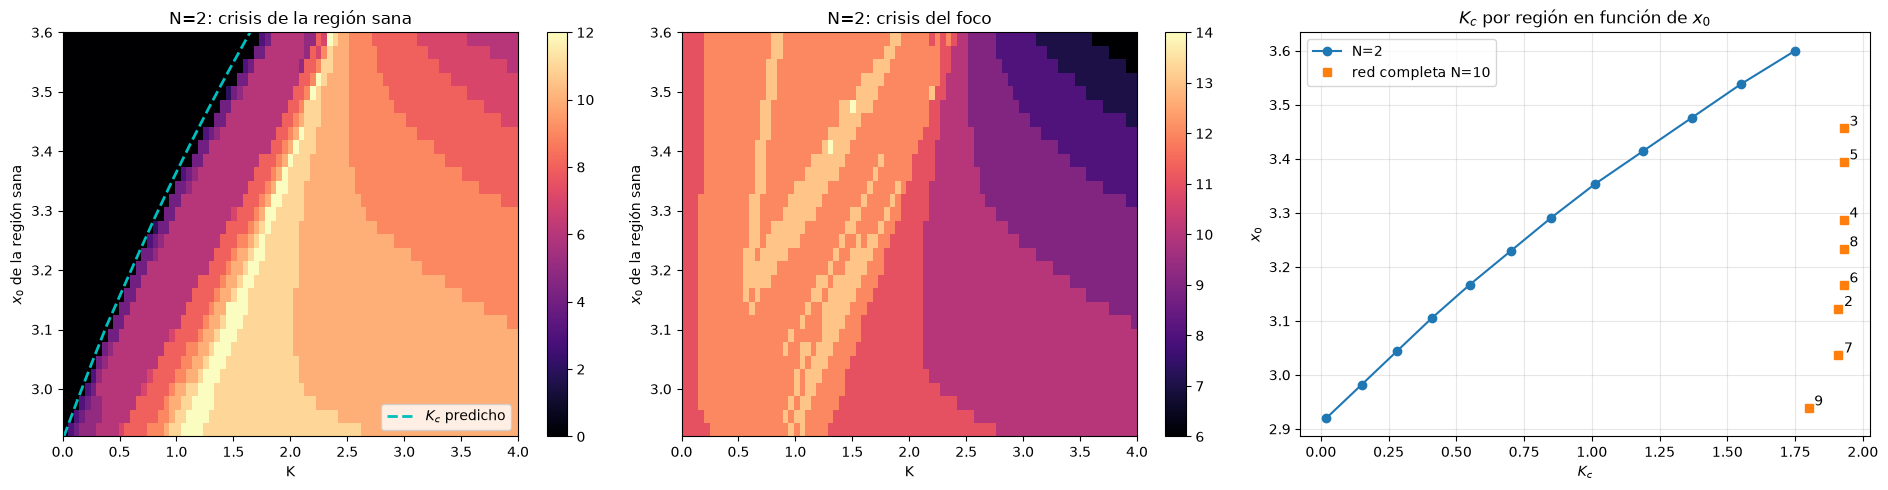

In [28]:
X02 = np.linspace(2.92, 3.6, 30)
K2 = np.linspace(0, 4, 81)
mapa_sana = np.zeros((len(X02), len(K2))); mapa_foco = np.zeros_like(mapa_sana)
t0 = time.time()
for a_, xv in enumerate(X02):
    r2 = em_red(np.array([2.3, xv]), A2, K2, T=60000, M=len(K2))
    mapa_sana[a_], mapa_foco[a_] = r2["n_on"][:, 1], r2["n_on"][:, 0]
print(f"({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ext = [K2[0], K2[-1], X02[0], X02[-1]]
for a, mapa, titulo in [(ax[0], mapa_sana, "crisis de la región sana"), (ax[1], mapa_foco, "crisis del foco")]:
    im = a.imshow(mapa, origin="lower", aspect="auto", extent=ext, cmap="magma")
    a.set(xlabel="K", ylabel="$x_0$ de la región sana", title=f"N=2: {titulo}")
    plt.colorbar(im, ax=a)
ax[0].plot(tabla_n2["K_c predicho (autoconsistente)"], tabla_n2["x0 sana"], "c--", lw=2, label="$K_c$ predicho")
ax[0].legend(loc="lower right")
ax[2].plot(tabla_n2["K_c simulado"], tabla_n2["x0 sana"], "o-", label="N=2")
ax[2].plot(kc_ec8[sanas], x0[sanas], "s", label="red completa N=10")
for i in np.where(sanas)[0]:
    ax[2].annotate(str(i), (kc_ec8[i], x0[i]), xytext=(4, 2), textcoords="offset points")
ax[2].set(xlabel="$K_c$", ylabel="$x_0$", title="$K_c$ por región en función de $x_0$")
ax[2].legend(); ax[2].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_diagrama_reclutamiento.png", dpi=200)
plt.show()

**Observaciones.**
- **N = 2:** la frontera de reclutamiento ($K_c$ de 0.02 a 1.75 cuando $x_0$ va de 2.92 a 3.6) crece casi linealmente con la barrera y coincide con la curva predicha.
- Para $K\gtrsim2.5$ y regiones sanas lejanas al umbral, el foco empieza a ser suprimido (panel central).
- **Red completa:** el $K_c$ por región es casi plano (1.80–1.93). Con 8 regiones sanas tirando hacia el reposo, nadie se recluta por separado: se reclutan todas en cascada detrás de la región 9.

# **B11. Efecto de retorno sobre el foco**

En la red completa las regiones sanas también actúan sobre el foco. Se mide, sin ruido y en función de $K$, la duración media de las crisis, el período y la fracción del tiempo en crisis del nodo 0. Se compara con el DAG del notebook anterior, también con acoplamiento $K/N$, donde el nodo 0 tiene grado de entrada 0.

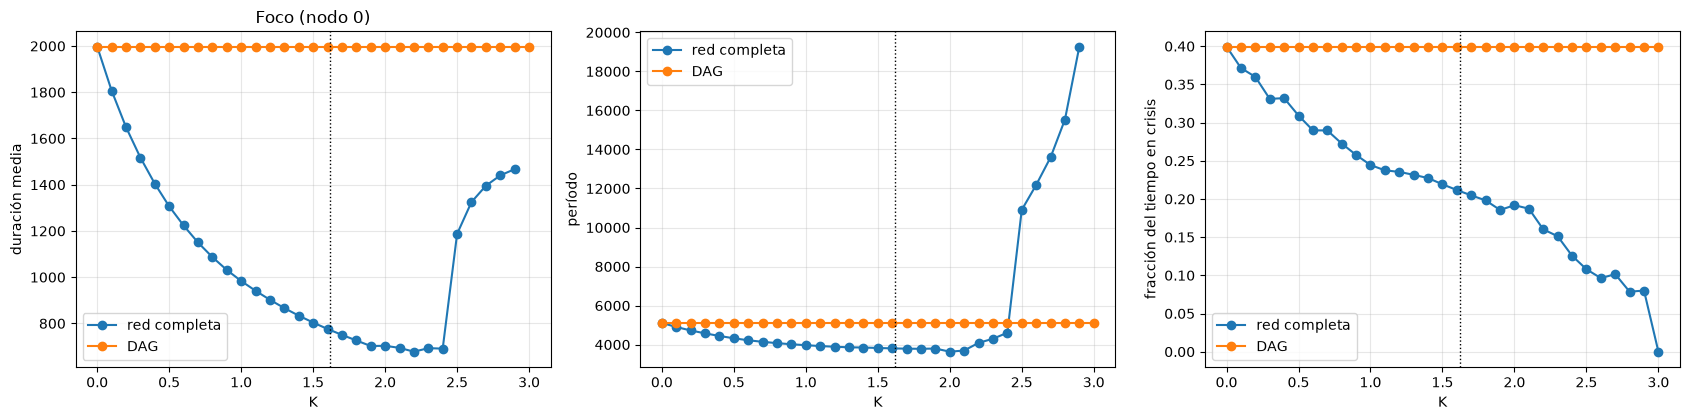

In [29]:
def estadisticas_crisis(s, t):
    on = np.where(s[1:] & ~s[:-1])[0] + 1
    off = np.where(~s[1:] & s[:-1])[0] + 1
    if len(on) == 0:
        return np.nan, np.nan, s.mean()
    off = off[off > on[0]]; n = min(len(on), len(off))
    dur = (t[off[:n]] - t[on[:n]]).mean() if n else np.nan
    per = np.diff(t[on]).mean() if len(on) > 1 else np.nan
    return dur, per, s.mean()

K_B11 = np.linspace(0, 3, 31)
ret_foco = {}
for nombre, Aest in [("red completa", A), ("DAG", A_DAG.astype(float))]:
    r = em_red(x0, Aest, K_B11, T=60000, M=len(K_B11), guardar=True, guardar_x=False, cada=10)
    ret_foco[nombre] = np.array([estadisticas_crisis(r["ict"][:, m, 0], r["t"]) for m in range(len(K_B11))])

fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for nombre, v in ret_foco.items():
    for a, k, ylab in zip(ax, range(3), ["duración media", "período", "fracción del tiempo en crisis"]):
        a.plot(K_B11, v[:, k], "o-", label=nombre); a.set(xlabel="K", ylabel=ylab)
ax[0].set_title("Foco (nodo 0)")
for a in ax:
    a.axvline(K_BASE, color="k", ls=":", lw=1); a.legend(); a.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_retorno_foco.png", dpi=200)
plt.show()

**Observaciones.**
- **Red completa:** al subir $K$ las sanas acortan las crisis del foco (de 2000 a ~700 en $K\approx2.2$), el período baja de 5100 a ~3700 y la fracción del tiempo en crisis cae de 0.40 a 0.21 en $K_{\rm base}$. Desde $K\approx2.4$ el período se dispara, y en $K=3$ el foco queda suprimido.
- **DAG:** las tres curvas son planas, porque el nodo 0 no recibe acoplamiento.
- **El efecto de retorno es grande:** en $K_{\rm base}$ el foco pasa la mitad de tiempo en crisis que aislado. Es la diferencia dinámica principal entre la red completa y el DAG.

# **C18. Acoplamiento rápido (en $x$) vs de permitividad (en $z$)**

Control: el acoplamiento difusivo actúa directamente en $x$, $dx_i\mathrel{+}=\frac{K}{N}\sum_jA_{ij}(x_j-x_i)\,dt$, y $z$ queda sin acoplar. Se repiten $K_c$, el enganche, los retrasos (B7) y el acuerdo con el DAG (B8).

In [30]:
K_X = np.linspace(0, 0.6, 61)
rx = em_red(x0, A, K_X, T=60000, M=len(K_X), acople="x")
cs = rx["n_on"][:, sanas].sum(1)
K_C_X = K_X[np.argmax(cs > 0)]
K_BASE_X = 0.9 * K_C_X
print(f"Acople en x: K_c = {K_C_X:.3f}, K_BASE = {K_BASE_X:.3f}")

nul_x = em_red(x0, A, np.repeat([0.0, K_BASE_X], R), SX, SZ_BASE, T=100000, M=2 * R, seed=33,
               guardar=True, guardar_x=False, cada=20, foco_mask=FOCO_EF, acople="x")
ev_x = [inicios(nul_x["ict"][:, m, :], nul_x["t"]) for m in range(2 * R)]

def resumen_acople(res, ev, K_c, K_b, nombre):
    sl = slice(R, 2 * R)
    on = res["n_on"][sl][:, RESTO].sum(1); onf = res["n_on_foco"][sl][:, RESTO].sum(1)
    with np.errstate(invalid="ignore", divide="ignore"):
        E_m = np.where(on > 0, onf / on, np.nan) / res["duty_foco"][sl]
    d = np.concatenate([retrasos(ev[m][i], np.sort(np.concatenate([ev[m][j] for j in np.where(FOCO_EF)[0]])))
                        for m in range(R, 2 * R) for i in np.where(RESTO)[0]])
    ac = np.array([acuerdo_con_dag(grafo_reclutamiento(ev[m], T_NUL, W_DIB))[0] for m in range(R, 2 * R)])
    return {"acoplamiento": nombre, "K_c": K_c, "K_BASE": K_b, "crisis fuera del foco ef./real.": on.mean(),
            "E": np.nanmean(E_m), "IC E": np.round(bootstrap_ic(E_m), 2), "retraso mediano": np.median(d) if len(d) else np.nan,
            "acuerdo DAG": np.nanmean(ac), "IC acuerdo": np.round(bootstrap_ic(ac), 3)}

tabla_c18 = pd.DataFrame([resumen_acople(nul, ev_nul, K_C, K_BASE, "permitividad (z)"),
                          resumen_acople(nul_x, ev_x, K_C_X, K_BASE_X, "rápido (x)")])
display(tabla_c18)

Acople en x: K_c = 0.170, K_BASE = 0.153


,acoplamiento,K_c,K_BASE,crisis fuera del foco ef./real.,E,IC E,retraso mediano,acuerdo DAG,IC acuerdo
0,permitividad (z),1.80,1.620,13.033333,2.362594,"[2.2, 2.52]",548.0,0.783838,"[0.745, 0.825]"
1,rápido (x),0.17,0.153,0.100000,2.600190,"[2.53, 2.71]",262.0,0.988889,"[0.967, 1.0]"


**Observaciones.**
- Con acoplamiento rápido (en $x$), $K_c=0.17$, unas 10 veces menor que con permitividad.
- Por debajo de $K_c$, el ruido casi no produce reclutamiento: 0.10 crisis por realización fuera del foco efectivo, contra 13.0 con permitividad.
- Las pocas crisis que hay están muy enganchadas ($E=2.60$, retraso mediano 262, acuerdo con el DAG 0.99), pero son muy pocos eventos.
- Interpretación: el acoplamiento en $z$ **acumula** el efecto del foco durante $\tau_0$ y acerca lentamente a las sanas a la rodilla, que es donde el ruido puede actuar. El acoplamiento en $x$ actúa de forma instantánea y no deja ese "pre-acondicionamiento".

# **C17. Validación con el Epileptor completo (6 variables)**

Se implementa el Epileptor de Jirsa et al. (2014) con el acoplamiento de permitividad de Proix et al. (2014, Ec. 1):

$$
\begin{aligned}
\dot x_1&=y_1-f_1(x_1,x_2)-z+I_1, & \dot y_1&=1-5x_1^2-y_1,\\
\dot z&=\tfrac{1}{\tau_0}\Big[h(x_1)-z-\tfrac{K}{N}\textstyle\sum_jA_{ij}(x_{1,j}-x_{1,i})\Big], &&\\
\dot x_2&=-y_2+x_2-x_2^3+I_2+2g-0.3(z-3.5), & \dot y_2&=\tfrac{1}{\tau_2}\big(-y_2+f_2(x_2)\big),\\
\dot g&=-\gamma g+x_1, &&
\end{aligned}
$$

con $f_1=x_1^3-3x_1^2$ si $x_1<0$, $f_1=(x_2-0.6(z-4)^2)\,x_1$ si $x_1\ge0$; $f_2=0$ si $x_2<-0.25$ y $f_2=6(x_2+0.25)$ en otro caso; $\tau_2=10$, $I_2=0.45$, $\gamma=0.01$ y $dt=0.05$, como en el paper. La crisis se detecta con histéresis en $x_1$: entra cuando $x_1>-0.5$ y sale cuando $x_1<-1.8$. Entre crisis $x_1$ baja a ~$-2$.

In [31]:
TAU2, I2, GAMMA = 10.0, 0.45, 0.01

@njit(parallel=True, cache=True)
def _epileptor6(x0, A_ptr, A_idx, A_val, K, n, dt, cada, X1):
    M = K.shape[0]; N = x0.shape[0]
    grado = np.zeros(N)
    for i in range(N):
        for p in range(A_ptr[i], A_ptr[i + 1]):
            grado[i] += A_val[p]
    for m in prange(M):
        x1 = np.full(N, -1.8); y1 = np.full(N, -15.0); z = x0.copy(); x2 = np.full(N, -0.9)
        y2 = np.zeros(N); g = np.full(N, -1.8 / GAMMA); nx1 = np.empty(N)
        KN = K[m] / N
        for k in range(1, n + 1):
            for i in range(N):
                ac = -grado[i] * x1[i]
                for p in range(A_ptr[i], A_ptr[i + 1]):
                    ac += A_val[p] * x1[A_idx[p]]
                f1 = x1[i]**3 - 3 * x1[i]**2 if x1[i] < 0 else (x2[i] - 0.6 * (z[i] - 4.0)**2) * x1[i]
                f2 = 0.0 if x2[i] < -0.25 else 6.0 * (x2[i] + 0.25)
                hx = x0[i] + 3.0 / (1.0 + np.exp(-(x1[i] + 0.5) / 0.1))
                nx1[i] = x1[i] + (y1[i] - f1 - z[i] + I1) * dt
                y1[i] += (1.0 - 5 * x1[i]**2 - y1[i]) * dt
                dz = (hx - z[i] - KN * ac) / TAU0
                dx2 = -y2[i] + x2[i] - x2[i]**3 + I2 + 2 * GAMMA * g[i] - 0.3 * (z[i] - 3.5)
                dy2 = (-y2[i] + f2) / TAU2
                dg = -GAMMA * g[i] + x1[i]
                z[i] += dz * dt; x2[i] += dx2 * dt; y2[i] += dy2 * dt; g[i] += dg * dt
            for i in range(N):
                x1[i] = nx1[i]
            if k % cada == 0:
                for i in range(N):
                    X1[k // cada - 1, m, i] = x1[i]

def epileptor6(x0_, W, K, T=60000, dt=0.05, M=1, cada=20, t_trans=5000):
    x0_ = np.asarray(x0_, float); W = np.asarray(W, float); nz = W != 0
    A_ptr = np.concatenate([[0], np.cumsum(nz.sum(1))]).astype(np.int64)
    A_idx = np.nonzero(nz)[1].astype(np.int64); A_val = W[nz]
    K = np.ascontiguousarray(np.broadcast_to(np.asarray(K, float), (M,)))
    n = int(round(T / dt)); X1 = np.empty((n // cada, M, len(x0_)), np.float32)
    _epileptor6(x0_, A_ptr, A_idx, A_val, K, n, dt, cada, X1)
    t = np.arange(1, n // cada + 1) * cada * dt
    S = np.zeros(X1.shape, bool); s = X1[0] > -0.5
    for k in range(len(t)):
        s = np.where(X1[k] > -0.5, True, np.where(X1[k] < -1.8, False, s)); S[k] = s
    S = S[t > t_trans]
    return (S[1:] & ~S[:-1]).sum(0)

x0_prueba = np.array([2.5, 2.85, 2.9, 2.92, 2.95, 3.0, 3.2])
print("Nodo aislado, crisis en 55 000 u.t.:", dict(zip(x0_prueba, epileptor6(x0_prueba, np.zeros((7, 7)), 0.0)[0])))

t0 = time.time()
K_C17 = np.round(np.linspace(1.5, 3.0, 76), 3)
n_ep6 = epileptor6(x0, A, K_C17, M=len(K_C17))
print(f"({time.time() - t0:.0f} s)")
kc_ep6 = np.array([K_C17[np.argmax(n_ep6[:, i] > 0)] if (n_ep6[:, i] > 0).any() else np.nan for i in range(N)])
K_C_EP6 = np.nanmin(kc_ep6[sanas])
tabla_c17 = pd.DataFrame({"x0": x0, "K_c Ec. 8": kc_ec8, "K_c Epileptor 6D": kc_ep6},
                         index=pd.Index(range(N), name="región"))[sanas].sort_values("x0")
display(tabla_c17)
rho_c17 = spearmanr(tabla_c17["K_c Ec. 8"], tabla_c17["K_c Epileptor 6D"])[0]
print(f"K_c: Ec. 8 = {np.nanmin(kc_ec8[sanas]):.3f}   Epileptor 6D = {K_C_EP6:.3f}   (cociente {K_C_EP6 / np.nanmin(kc_ec8[sanas]):.2f})")
print(f"Spearman del orden de reclutamiento: {rho_c17:.2f}")

Nodo aislado, crisis en 55 000 u.t.: {np.float64(2.5): np.int64(9), np.float64(2.85): np.int64(5), np.float64(2.9): np.int64(4), np.float64(2.92): np.int64(0), np.float64(2.95): np.int64(0), np.float64(3.0): np.int64(0), np.float64(3.2): np.int64(0)}


(13 s)


,x0,K_c Ec. 8,K_c Epileptor 6D
región,,,
9,2.938290,1.80,2.34
7,3.036343,1.91,2.50
2,3.122479,1.91,2.50
6,3.166049,1.93,2.50
8,3.232751,1.93,2.52
4,3.286319,1.93,2.52
5,3.393657,1.93,2.52
3,3.456059,1.93,2.52


K_c: Ec. 8 = 1.800   Epileptor 6D = 2.340   (cociente 1.30)
Spearman del orden de reclutamiento: 0.84


**Observaciones.**
- El Epileptor completo reproduce el umbral: un nodo aislado tiene crisis con $x_0\le2.90$ y no con $x_0\ge2.92$.
- En la red completa, $K_c=2.34$ contra 1.80 con la Ec. 8. La escala es 1.3 veces mayor, porque la crisis del modelo completo cambia el promedio de $x_1$.
- **El orden se conserva:** primero la 9, luego 7, 2 y 6 (en $K=2.50$) y al final 8, 4, 5 y 3 (en $K=2.52$). El Spearman del orden entre ambos modelos es 0.84.
- La Ec. 8 captura la jerarquía de reclutamiento del modelo completo.

# **C15. Conectividad estructural no trivial**

Se repiten A3, B7, B8 y C13 con matrices estructurales distintas de la red completa:

- **C15a. SBM:** modelo de bloques estocástico con 3 módulos de 10 regiones, $p_{\rm in}=0.8$, $p_{\rm out}=0.05$; el foco está en el módulo 0.
- **C15b. Pesos lognormales:** red completa con pesos simétricos $K_{ij}\sim\mathrm{LogNormal}(0,0.5)$.
- **C15c. Conectoma real:** conectoma por defecto de TVB (76 regiones; se quitan las 2 aisladas, que corresponden al cuerpo calloso). El foco está en el hipocampo y la amígdala derechos, como en Proix et al. (2014).

Los pesos se simetrizan y se reescalan a fuerza media $N-1$. Los $x_0$ sanos se acotan a $\ge2.92$, para que no aparezcan focos que no fueron elegidos. Si no hay $K_c$ determinista, $K_{\rm base}$ se fija en un valor de referencia `K_ref`, por debajo de la supresión del foco.

In [32]:
def normalizar(W):
    W = (W + W.T) / 2
    np.fill_diagonal(W, 0)
    return W * (len(W) - 1) / W.sum(1).mean()

def analizar_estructura(nombre, x0_, W, Ks, K_ref=None, R_=R, T=100000, seed=1):
    t0 = time.time(); n = len(x0_); foco_ = x0_ < X0_C; sanas_ = ~foco_
    kc, rdet = kc_por_region(x0_, W, Ks)
    K_c = np.nanmin(kc[sanas_]) if np.isfinite(kc[sanas_]).any() else np.nan
    sup = rdet["n_on"][:, foco_].sum(1) == 0
    K_sup = Ks[np.argmax(sup)] if sup.any() else np.nan
    K_b = 0.9 * K_c if np.isfinite(K_c) else K_ref
    r = em_red(x0_, W, np.repeat([0.0, K_b], R_), SX, SZ_BASE, T=T, M=2 * R_, seed=seed,
               guardar=True, guardar_x=False, cada=20)
    P = (r["n_on"] > 0).reshape(2, R_, n).mean(1)
    ef = foco_ | (P[0] > 0.5); resto = ~ef
    ev = [inicios(r["ict"][:, m, :], r["t"]) for m in range(2 * R_)]
    Tt = r["t"][-1]
    E = []
    for kk in range(2):
        on = onf = 0; df = 0.0
        for m in range(kk * R_, (kk + 1) * R_):
            Sf = r["ict"][:, m, ef].any(1); df += Sf.mean() / R_
            idx = np.searchsorted(r["t"], np.concatenate([ev[m][i] for i in np.where(resto)[0]] + [np.array([])]))
            on += len(idx); onf += Sf[np.clip(idx, 0, len(Sf) - 1)].sum()
        E.append(onf / on / df if on and df > 0 else np.nan)
    A_dag_ = x0_[None, :] < x0_[:, None]
    ac = np.array([acuerdo_con_dag(grafo_reclutamiento(ev[m], Tt, W_DIB), A_dag_) for m in range(R_, 2 * R_)], float)
    d = np.concatenate([retrasos(ev[m][i], np.sort(np.concatenate([ev[m][j] for j in np.where(ef)[0]])))
                        for m in range(R_, 2 * R_) for i in np.where(resto)[0]] + [np.array([])])
    pred = kc_predicho(x0_, W, K_b)
    ok = sanas_ & np.isfinite(kc) & np.isfinite(pred)
    i1 = np.where(sanas_)[0][np.nanargmin(kc[sanas_])] if np.isfinite(K_c) else None
    fila = {"estructura": nombre, "N": n, "K_c": K_c, "K de supresión del foco": K_sup, "K_BASE": K_b,
            "foco efectivo": list(np.where(ef)[0]), "crisis fuera del foco ef. K=0": r["n_on"][:R_][:, resto].sum(1).mean(),
            "crisis fuera del foco ef. K_BASE": r["n_on"][R_:][:, resto].sum(1).mean(), "E K=0": E[0], "E K_BASE": E[1],
            "retraso mediano": np.median(d) if len(d) else np.nan,
            "acuerdo DAG": np.nanmean(ac[:, 0]), "IC acuerdo": np.round(bootstrap_ic(ac[:, 0]), 3),
            "pares/real.": ac[:, 1].mean(),
            "ρ(K_c pred, sim)": spearmanr(pred[ok], kc[ok])[0] if ok.sum() > 2 else np.nan,
            "error 1.ª reclutada": pred[i1] / K_c - 1 if i1 is not None else np.nan,
            "s": round(time.time() - t0)}
    reg = pd.DataFrame({"x0": x0_, "barrera": x0_ - Z_RODILLA, "K_c simulado": kc, "K_c predicho": pred,
                        "P(crisis) K=0": P[0], "P(crisis) K_BASE": P[1], "W hacia el foco": W[:, foco_].sum(1)})
    return fila, reg

def x0_estructura(n, seed=SEED, focos=(0, 1)):
    x = np.maximum(np.random.default_rng(seed).uniform(2.9, 3.5, n), 2.92)
    x[list(focos)] = [2.3, 2.4][:len(focos)]
    return x

resultados_c15, regiones_c15 = [], {}

f, reg = analizar_estructura("completa (referencia)", x0, A.astype(float), K_C13)
resultados_c15.append(f); regiones_c15["completa"] = reg

L = np.random.default_rng(SEED).lognormal(0, 0.5, (N, N))
W_logn = normalizar(L * A)
f, reg = analizar_estructura("C15b pesos lognormales", x0, W_logn, np.round(np.linspace(0.5, 3.0, 126), 3))
resultados_c15.append(f); regiones_c15["lognormal"] = reg

N_SBM, TAM = 30, [10, 10, 10]
G_sbm = nx.stochastic_block_model(TAM, [[0.8, 0.05, 0.05], [0.05, 0.8, 0.05], [0.05, 0.05, 0.8]], seed=SEED)
W_sbm = normalizar(nx.to_numpy_array(G_sbm))
x0_sbm = x0_estructura(N_SBM)
modulo_sbm = np.repeat(np.arange(3), 10)
f, reg = analizar_estructura("C15a SBM 3×10", x0_sbm, W_sbm, np.round(np.linspace(0.25, 6.0, 116), 3))
reg["módulo"] = modulo_sbm
resultados_c15.append(f); regiones_c15["SBM"] = reg

In [33]:
URL_TVB = "https://github.com/the-virtual-brain/tvb-data/raw/master/tvb_data/connectivity/connectivity_76.zip"
ruta_tvb = Path("datos") / "connectivity_76.zip"
if not ruta_tvb.exists():
    ruta_tvb.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_TVB, ruta_tvb)
with zipfile.ZipFile(ruta_tvb) as zf:
    W_raw = np.loadtxt(io.TextIOWrapper(zf.open("weights.txt")))
    etiquetas_tvb = [l.split()[0] for l in io.TextIOWrapper(zf.open("centres.txt"))]
mantener = [i for i, l in enumerate(etiquetas_tvb) if l not in ("rCC", "lCC")]
W_tvb = normalizar(W_raw[np.ix_(mantener, mantener)])
etiquetas_tvb = [etiquetas_tvb[i] for i in mantener]
N_TVB = len(W_tvb)
focos_tvb = [etiquetas_tvb.index("rHC"), etiquetas_tvb.index("rAMYG")]
x0_tvb = x0_estructura(N_TVB, focos=focos_tvb)
print(f"TVB: N = {N_TVB}, componentes conexas = {nx.number_connected_components(nx.from_numpy_array(W_tvb))}, "
      f"grado medio = {(W_tvb > 0).sum(1).mean():.1f}, foco = {[etiquetas_tvb[i] for i in focos_tvb]}")

f, reg = analizar_estructura("C15c conectoma TVB", x0_tvb, W_tvb, np.round(np.linspace(0.5, 16, 32), 3),
                             K_ref=4.0, R_=10, T=60000)
reg["etiqueta"] = etiquetas_tvb
resultados_c15.append(f); regiones_c15["TVB"] = reg

tabla_c15 = pd.DataFrame(resultados_c15)
display(tabla_c15)

TVB: N = 74, componentes conexas = 1, grado medio = 23.8, foco = ['rHC', 'rAMYG']


,estructura,N,K_c,K de supresión del foco,K_BASE,foco efectivo,crisis fuera del foco ef. K=0,crisis fuera del foco ef. K_BASE,E K=0,E K_BASE,retraso mediano,acuerdo DAG,IC acuerdo,pares/real.,"ρ(K_c pred, sim)",error 1.ª reclutada,s
0,completa (referencia),10,1.80,NaN,1.620,"[0, 1, 9]",0.000000,11.900000,NaN,2.224979,584.0,0.776891,"[0.738, 0.819]",37.900000,0.866025,-0.045418,15
1,C15b pesos lognormales,10,1.84,2.82,1.656,"[0, 1, 9]",0.000000,1.033333,NaN,1.778708,690.0,0.962593,"[0.923, 0.997]",8.133333,0.577350,0.006142,16
2,C15a SBM 3×10,30,1.45,2.75,1.305,"[0, 1, 4, 8, 17, 27, 28]",0.133333,0.033333,0.708295,2.867284,552.0,0.868889,"[0.847, 0.893]",6.133333,0.927778,-0.107699,46
3,C15c conectoma TVB,74,NaN,9.00,4.000,"[2, 4, 8, 9, 17, 27, 51, 58, 59, 68]",1.500000,0.000000,1.269734,NaN,NaN,0.400000,"[0.1, 0.7]",1.000000,NaN,NaN,43


,estructura,regiones sanas reclutables (K_c finito),"ρ(K_c, barrera)","ρ(K_c, −W hacia el foco)"
0,completa,8 de 8,0.866025,NaN
1,lognormal,8 de 8,0.577350,-0.082479
2,SBM,8 de 28,0.698846,0.897538
3,TVB,0 de 72,NaN,NaN


SBM, por módulo (regiones sanas):


,barrera,W_foco,reclutables,K_c_medio,P_K_BASE
módulo,,,,,
0,0.342,5.026,8,2.212,0.254
1,0.316,0.731,0,NaN,0.000
2,0.303,0.000,0,NaN,0.000


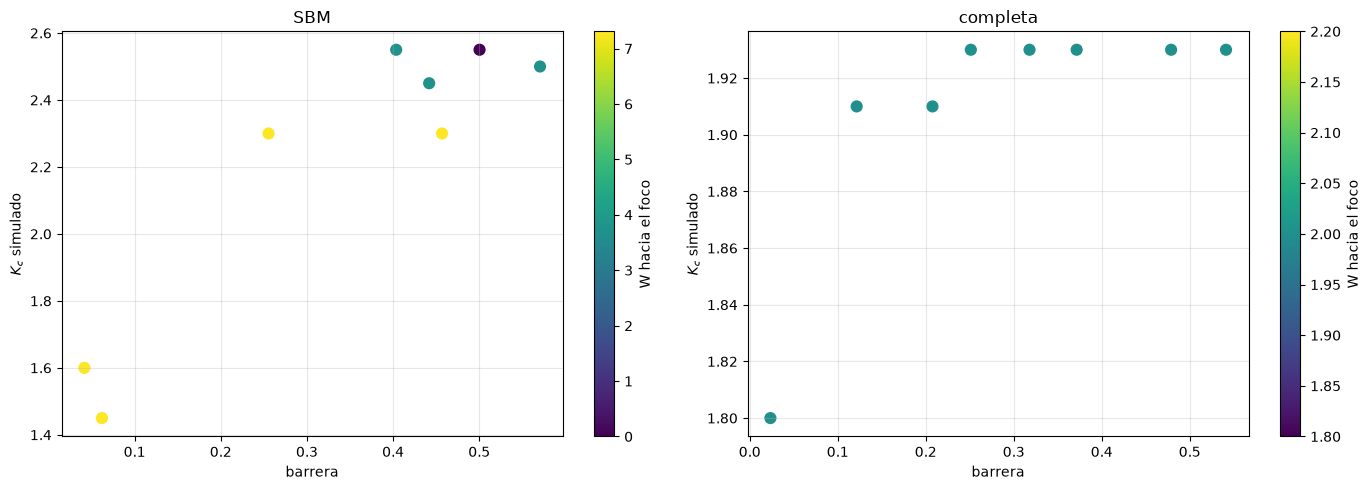

In [34]:
filas = []
for nombre, reg in regiones_c15.items():
    s = reg[reg["x0"] >= X0_C]
    ok = np.isfinite(s["K_c simulado"])
    filas.append({"estructura": nombre, "regiones sanas reclutables (K_c finito)": f"{ok.sum()} de {len(s)}",
                  "ρ(K_c, barrera)": spearmanr(s["K_c simulado"][ok], s["barrera"][ok])[0] if ok.sum() > 2 else np.nan,
                  "ρ(K_c, −W hacia el foco)": spearmanr(s["K_c simulado"][ok], -s["W hacia el foco"][ok])[0] if ok.sum() > 2 else np.nan})
display(pd.DataFrame(filas))

s = regiones_c15["SBM"]
print("SBM, por módulo (regiones sanas):")
display(s[s["x0"] >= X0_C].groupby("módulo").agg(barrera=("barrera", "mean"), W_foco=("W hacia el foco", "mean"),
                                                  reclutables=("K_c simulado", lambda v: np.isfinite(v).sum()),
                                                  K_c_medio=("K_c simulado", "mean"), P_K_BASE=("P(crisis) K_BASE", "mean")).round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, nombre in zip(ax, ["SBM", "completa"]):
    s = regiones_c15[nombre]; s = s[s["x0"] >= X0_C]
    sc = a.scatter(s["barrera"], s["K_c simulado"], c=s["W hacia el foco"], cmap="viridis", s=60)
    plt.colorbar(sc, ax=a, label="W hacia el foco")
    a.set(xlabel="barrera", ylabel="$K_c$ simulado", title=nombre); a.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "dn_estructuras.png", dpi=200)
plt.show()

**Observaciones.**
- **Pesos lognormales (C15b):** el $K_c$ sin ruido casi no cambia (1.84), pero con ruido hay mucho menos reclutamiento (1.0 contra 11.9 crisis por realización). Las regiones con pesos débiles hacia el foco quedan protegidas. El acuerdo con el DAG es 0.96, aunque con pocos pares (8).
- **SBM (C15a):**
  - $K_c=1.45$. Solo se reclutan regiones del **módulo del foco** (8 de 28 sanas); los módulos 1 y 2 nunca, antes de que el foco quede suprimido en $K=2.75$.
  - El acoplamiento hacia el foco predice el $K_c$ mejor que la barrera: $\rho=0.90$ contra 0.70. **La topología sí predice el reclutamiento.**
  - La predicción analítica correlaciona con $\rho=0.93$ y su error en la primera reclutada es −11 %.
  - El foco efectivo del SBM es grande (7 regiones): al acotar $x_0\ge2.92$ quedan regiones con barrera 0.005, que tienen crisis solas por ruido.
- **Conectoma TVB (C15c):** no hay $K_c$; el foco queda suprimido en $K=9$. Con ruido, las crisis fuera del foco efectivo bajan de 1.5 ($K=0$) a 0 ($K_{\rm ref}=4$). Con $K/N$ y $x_0$ sanos uniformes, **la red es protectora**. El hipocampo derecho tiene solo 7 vecinos y su influencia se diluye frente a la de vecinos sanos con fuerza ~40.

# **C16. Lugar del foco en la red**

En el SBM y en el conectoma TVB se coloca un **único foco** ($x_0=2.3$) en el nodo de mayor y de menor centralidad (grado ponderado, intermediación y autovector). Las demás regiones conservan sus $x_0$ sanos. Sin ruido se mide $K_c$, el número máximo de regiones reclutadas en el barrido y el $K$ desde el que el foco queda suprimido.

In [35]:
def lugar_del_foco(W, x0_base, Ks, nombre, etiquetas_=None):
    G_ = nx.from_numpy_array(W)
    G_dist = nx.from_numpy_array(np.where(W > 0, 1 / np.where(W > 0, W, 1), 0))
    cent = {"grado": dict(G_.degree(weight="weight")),
            "intermediación": nx.betweenness_centrality(G_dist, weight="weight"),
            "autovector": dict(enumerate(np.abs(np.linalg.eigh(W)[1][:, -1])))}
    filas = []
    for c_nombre, c in cent.items():
        v = np.array([c[i] for i in range(len(W))])
        for tipo, nodo in [("máxima", int(np.argmax(v))), ("mínima", int(np.argmin(v)))]:
            xx = x0_base.copy(); xx[nodo] = 2.3
            r = em_red(xx, W, Ks, T=60000, M=len(Ks))
            sanas_ = np.arange(len(W)) != nodo
            rec = (r["n_on"][:, sanas_] > 0).sum(1)
            sup = r["n_on"][:, nodo] == 0
            filas.append({"red": nombre, "centralidad": c_nombre, "tipo": tipo,
                          "nodo": etiquetas_[nodo] if etiquetas_ else nodo, "valor": v[nodo],
                          "grado binario": int((W[nodo] > 0).sum()),
                          "K_c": Ks[np.argmax(rec > 0)] if (rec > 0).any() else np.nan,
                          "máx. reclutadas": int(rec.max()), "K de supresión": Ks[np.argmax(sup)] if sup.any() else np.nan})
    return pd.DataFrame(filas)

t0 = time.time()
x0_sbm_base = x0_sbm.copy(); x0_sbm_base[[0, 1]] = np.maximum(np.random.default_rng(7).uniform(2.9, 3.5, 2), 2.92)
x0_tvb_base = x0_tvb.copy(); x0_tvb_base[focos_tvb] = np.maximum(np.random.default_rng(7).uniform(2.9, 3.5, 2), 2.92)
tabla_c16 = pd.concat([lugar_del_foco(W_sbm, x0_sbm_base, np.round(np.linspace(0.25, 8.0, 32), 3), "SBM"),
                       lugar_del_foco(W_tvb, x0_tvb_base, np.round(np.linspace(0.5, 16, 24), 3), "TVB", etiquetas_tvb)],
                      ignore_index=True)
print(f"({time.time() - t0:.0f} s)")
display(tabla_c16.round(3))

(95 s)


,red,centralidad,tipo,nodo,valor,grado binario,K_c,máx. reclutadas,K de supresión
0,SBM,grado,máxima,12,40.210,11,NaN,0,1.500
1,SBM,grado,mínima,26,14.622,4,NaN,0,4.250
2,SBM,intermediación,máxima,5,0.156,9,NaN,0,1.750
3,SBM,intermediación,mínima,15,0.001,7,NaN,0,2.250
4,SBM,autovector,máxima,19,0.308,10,NaN,0,1.750
5,SBM,autovector,mínima,26,0.032,4,NaN,0,4.250
6,TVB,grado,máxima,rPFCORB,119.294,34,NaN,0,1.174
7,TVB,grado,mínima,rHC,15.148,7,NaN,0,8.587
8,TVB,intermediación,máxima,lCCA,0.176,31,NaN,0,1.848
9,TVB,intermediación,mínima,rA2,0.000,21,NaN,0,2.522


**Observaciones.**
- **Un foco único no recluta a ninguna región** en ninguna de las 12 ubicaciones (SBM y TVB): la red lo suprime antes.
- La centralidad decide **cuándo** lo suprime:
  - un foco en el nodo de mayor grado es suprimido en $K\approx1.2$–$1.8$;
  - en el de menor grado, en $K\approx4$ (SBM) y $K\approx9$ (TVB).
- En el SBM principal hubo reclutamiento porque había **dos** focos en el mismo módulo y vecinos cerca del umbral.
- Con acoplamiento difusivo de permitividad, ser central protege a la red en lugar de facilitar la propagación.

# **D22. Tabla final de hipótesis**

La tabla se arma con los números calculados en el notebook.

In [36]:
fila_c = tabla_reclut[(tabla_reclut.K == round(K_BASE, 3)) & (tabla_reclut["σz"] == SZ_BASE)].iloc[0]
fila_0 = tabla_reclut[(tabla_reclut.K == 0.0) & (tabla_reclut["σz"] == SZ_BASE)].iloc[0]
d_B = ret[(K_BASE, "foco efectivo")]
fila_dag = tabla_dag[(tabla_dag.ventana == W_DIB) & (tabla_dag.K == round(K_BASE, 3))].iloc[0]
sbm = regiones_c15["SBM"]; sbm = sbm[sbm["x0"] >= X0_C]
kc_mod = sbm.groupby("módulo")["K_c simulado"].apply(lambda v: np.nanmean(v) if np.isfinite(v).any() else np.inf)
fila_tvb = tabla_c15[tabla_c15.estructura.str.contains("TVB")].iloc[0]
rho_sup = {red: spearmanr(g["grado binario"], g["K de supresión"])[0] for red, g in tabla_c16.groupby("red")}

def veredicto(cond):
    return "acepta" if cond else "rechaza"

hipotesis = pd.DataFrame([
    {"hipótesis": "El ruido solo no recluta (control K=0)",
     "resultado": veredicto(fila_0["crisis fuera del foco ef./realización"] < 0.1),
     "evidencia": f"crisis fuera del foco ef. con K=0: {fila_0['crisis fuera del foco ef./realización']:.2f}/realización (Sec. 3.2)"},
    {"hipótesis": "Reclutamiento por la red (E > 1)",
     "resultado": veredicto(fila_c["IC E"][0] > 1),
     "evidencia": f"E = {fila_c['E']:.2f}, IC {fila_c['IC E']} con K_BASE; {fila_c['crisis fuera del foco ef./realización']:.1f} crisis/realización (dn_reclutamiento_control.png)"},
    {"hipótesis": "Dirección foco → sanas (B7)",
     "resultado": veredicto(len(d_B) > 0 and len(ret[(0.0, "foco efectivo")]) < 0.1 * len(d_B)),
     "evidencia": f"{len(d_B)} inicios con K_BASE vs {len(ret[(0.0, 'foco efectivo')])} con K=0; retraso mediano {np.median(d_B):.0f} (dn_retrasos.png)"},
    {"hipótesis": "La dinámica recupera el DAG (B8)",
     "resultado": veredicto(fila_dag["IC 95 %"][0] > 0.5 and p_dag < 0.05),
     "evidencia": f"acuerdo {fila_dag['acuerdo medio']:.3f}, IC {fila_dag['IC 95 %']}; surrogados p = {p_dag:.4f} (dn_grafo_funcional_vs_dag.png)"},
    {"hipótesis": "La predicción analítica coincide con la simulación (C13)",
     "resultado": veredicto(abs(err_red) < 0.1 and tabla_n2["error relativo"].abs().median() < 0.1),
     "evidencia": f"error en la 1.ª reclutada de la red {100 * err_red:+.1f} %; error mediano N=2 {100 * tabla_n2['error relativo'].abs().median():.1f} % (dn_prediccion_kc.png)"},
    {"hipótesis": "La topología predice el reclutamiento (C15 SBM)",
     "resultado": veredicto(kc_mod.idxmin() == 0),
     "evidencia": "K_c medio de las sanas por módulo: " + ", ".join(
         f"módulo {k}: {v:.2f}" if np.isfinite(v) else f"módulo {k}: sin reclutamiento" for k, v in kc_mod.items())
         + " (el foco está en el módulo 0)"},
    {"hipótesis": "El conectoma real recluta con K/N (C15c)",
     "resultado": veredicto(np.isfinite(fila_tvb["K_c"])),
     "evidencia": f"K_c = {fila_tvb['K_c']}, supresión del foco en K = {fila_tvb['K de supresión del foco']}; crisis fuera del foco ef.: {fila_tvb['crisis fuera del foco ef. K=0']:.2f} (K=0) → {fila_tvb['crisis fuera del foco ef. K_BASE']:.2f} (K_ref)"},
    {"hipótesis": "Un foco único recluta según su centralidad (C16)",
     "resultado": veredicto(tabla_c16["máx. reclutadas"].max() > 0),
     "evidencia": f"máx. regiones reclutadas en las 12 ubicaciones (SBM y TVB): {tabla_c16['máx. reclutadas'].max()}"},
    {"hipótesis": "Un foco más central es suprimido antes por la red (C16)",
     "resultado": veredicto(all(v < -0.5 for v in rho_sup.values())),
     "evidencia": "ρ(grado binario, K de supresión): " + ", ".join(f"{k} {v:.2f}" for k, v in rho_sup.items())},
    {"hipótesis": "El Epileptor 6D reproduce el orden de reclutamiento (C17)",
     "resultado": veredicto(rho_c17 > 0.5),
     "evidencia": f"K_c 6D = {K_C_EP6:.2f} vs Ec. 8 = {np.nanmin(kc_ec8[sanas]):.2f}; Spearman del orden = {rho_c17:.2f}"},
])
with pd.option_context("display.max_colwidth", 200):
    display(hipotesis)

,hipótesis,resultado,evidencia
0,El ruido solo no recluta (control K=0),acepta,crisis fuera del foco ef. con K=0: 0.00/realización (Sec. 3.2)
1,Reclutamiento por la red (E > 1),acepta,"E = 2.24, IC [2.02 2.47] con K_BASE; 7.0 crisis/realización (dn_reclutamiento_control.png)"
2,Dirección foco → sanas (B7),acepta,391 inicios con K_BASE vs 0 con K=0; retraso mediano 548 (dn_retrasos.png)
3,La dinámica recupera el DAG (B8),acepta,"acuerdo 0.784, IC [0.745 0.825]; surrogados p = 0.0050 (dn_grafo_funcional_vs_dag.png)"
4,La predicción analítica coincide con la simulación (C13),acepta,error en la 1.ª reclutada de la red -4.5 %; error mediano N=2 5.5 % (dn_prediccion_kc.png)
5,La topología predice el reclutamiento (C15 SBM),acepta,"K_c medio de las sanas por módulo: módulo 0: 2.21, módulo 1: sin reclutamiento, módulo 2: sin reclutamiento (el foco está en el módulo 0)"
6,El conectoma real recluta con K/N (C15c),rechaza,"K_c = nan, supresión del foco en K = 9.0; crisis fuera del foco ef.: 1.50 (K=0) → 0.00 (K_ref)"
7,Un foco único recluta según su centralidad (C16),rechaza,máx. regiones reclutadas en las 12 ubicaciones (SBM y TVB): 0
8,Un foco más central es suprimido antes por la red (C16),acepta,"ρ(grado binario, K de supresión): SBM -0.99, TVB -1.00"
9,El Epileptor 6D reproduce el orden de reclutamiento (C17),acepta,K_c 6D = 2.34 vs Ec. 8 = 1.80; Spearman del orden = 0.84


# **Conclusiones (D20)**

1. **Estructura homogénea.** En la red completa ninguna región se distingue estructuralmente, por construcción. La jerarquía de reclutamiento la fija la **distancia de $x_0$ al umbral** (la barrera $x_{0,i}-z_{\rm rodilla}$), y la dinámica **reconstruye el DAG impuesto antes**: acuerdo 0.78 [0.75, 0.83], contra 0.42 en los surrogados ($p=0.005$). Agrega un elemento que el DAG no tiene: el **efecto de retorno** de las sanas sobre el foco, que reduce su tiempo en crisis a la mitad.
2. **El reclutamiento lo dispara el ruido y lo hace posible la red.** Con $K=0$ hay cero crisis sanas. Con $K_{\rm base}=0.9K_c$ hay 7 crisis por realización y $E=2.24$ [2.02, 2.47]. El ruido solo o la red sola no bastan.
3. **Cadena de reclutamiento:** $\{0,1\}\to9\to7\to2\to6\to8\to4\to5\to3$. La región 9, en la zona umbral, es el **puente** entre el foco y el resto. El Epileptor completo confirma el orden (Spearman 0.84).
4. **Teoría.** El reclutamiento se predice con el acoplamiento **filtrado** por $\tau_0$ (−4.5 % en la red y ~5 % en N = 2), no con su promedio. La predicción individual falla para las regiones que entran en cascada.
5. **Topología.** En un SBM, la conexión al foco predice el reclutamiento mejor que la barrera. En el conectoma real (TVB), con $K/N$, la red es **protectora**. Un foco único es suprimido antes de reclutar, y más pronto cuanto más central es.
6. **Modularidad:** resultado negativo. Bajo ruido, $Q$ es mayor sin red que con red; el análisis útil es dirigido (B7 y B8).

**Limitaciones.**
- La elección de $\sigma_z$ fija el tamaño del foco efectivo.
- Los $x_0$ sanos aleatorios (y su acotamiento en 2.92) generan regiones casi en el umbral.
- En TVB los $x_0$ son aleatorios y no hay una zona de propagación diseñada como en Proix et al.
- La normalización $K/N$ penaliza a los focos con pocos vecinos.